# LLMs and the Organization of Scientific Teams

This script reproduces all figures and tables in our analysis, in the order
they appear in the paper (from the main results to the appendix).

The sample, the metrics and the estimator live in `analysis/`, and each block
below calls the same functions as `run_analysis.py`.

In [1]:
# Run this first. It makes sure the notebook is working inside the
# llms_scientific_work folder, whatever directory Jupyter was started from.
import os
import sys
from pathlib import Path


def find_root():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "analysis" / "config.py").exists():
            return p
    
    cands = [here / "llms_scientific_work", here / "llms_scientific_work" / "llms_scientific_work",
             Path.home() / "Downloads" / "llms_scientific_work",
             Path.home() / "Downloads" / "llms_scientific_work" / "llms_scientific_work"]
    for p in cands:
        if (p / "analysis" / "config.py").exists():
            return p

    for base in (Path.home() / "Downloads", Path.home() / "Documents"):
        if base.exists():
            for hit in base.rglob("analysis/config.py"):
                return hit.parent.parent
    raise SystemExit(
        "Could not find the llms_scientific_work folder. Set it by hand:\n"
        "    os.chdir(r'C:\\path\\to\\llms_scientific_work')")


ROOT = find_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("working in", ROOT)

working in C:\Users\iogec\Downloads\llms_scientific_work\llms_scientific_work


## Setup

In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import pandas as pd
from IPython.display import display

from analysis import config as C
from analysis import figures as F
from analysis import tables as T
from analysis.build import load_clean
from analysis.build import load_papers
from analysis.estimation import run_event_studies
from analysis.sample import estimation_sample, team_subset
import run_analysis as R

F.show_figures(True)            # draw each figure here as well as saving it
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 80)

## Block 0 — data and the estimation sample
From an initial sample of 121,792 publications labelled as research articles with team size between 2 and 100, we remove publications whose CRediT statements are entirely or partially missing (resulting in 119,815 obs), those with no author matched to the publication-history panel (and therefore without team-level controls), those with missing control values, and those without a primary field. This leaves 117,211 papers, the estimation sample for everything that follows.

In [3]:
papers = load_papers(force=True)          # load_papers(force=True) to re-parse the raw files
d, controls, labels = estimation_sample(papers)

print(controls)
d.head(3)

prepared table : 121,792 rows, 15 columns
  empty dict            : 0
  >= 1 author N/A       : 1,977
  kept                  : 119,815
cached clean -> C:\Users\iogec\Downloads\llms_scientific_work\llms_scientific_work\cache\clean.parquet (42 MB, 119,815 rows)
  field levels after collapsing rare (<50): 26
papers table : 119,815 rows x 59 cols
cached papers -> C:\Users\iogec\Downloads\llms_scientific_work\llms_scientific_work\cache\papers.parquet
papers                            : 119,815
  1. duplicate / missing DOIs     : 36 -> 119,779
  2. outside 2018-2025            : 0 -> 119,779
  3. no matched author list       : 2,512 -> 117,267
     log_size             missing for 0
     log_iic              missing for 0
     log_avg_pubs_auth    missing for 0
     log_academic_age     missing for 56
  4. incomplete controls          : 56 -> 117,211
  5. no primary field             : 0 -> 117,211

ESTIMATION SAMPLE : 117,211 papers
  = the 117,211 papers of the paper
  team_type : {'hybri

,seed_doi,doi_norm,seed_year,publication_date,team_type,team_size,paper_primary_field,paper_primary_domain,avg_tasks_per_author,avg_jaccard,avg_tasks_per_author14,avg_jaccard14,author_ids,n_conceptualization,share_conceptualization,n_methodology,share_methodology,n_software,share_software,n_validation,share_validation,n_formal_analysis,share_formal_analysis,n_investigation,share_investigation,n_resources,share_resources,n_data_curation,share_data_curation,n_writing_original_draft,share_writing_original_draft,n_writing_review_editing,share_writing_review_editing,n_visualization,share_visualization,n_supervision,share_supervision,n_project_administration,share_project_administration,n_funding_acquisition,share_funding_acquisition,n_grp_ideation,share_grp_ideation,n_grp_data_and_coding,share_grp_data_and_coding,n_grp_execution,share_grp_execution,n_grp_communication,share_grp_communication,n_grp_coordination,share_grp_coordination,n_grp_funding_resources,share_grp_funding_resources,n_authors_bq,avg_pubs_per_author,iic,avg_academic_age,n_authors_info,collab_ratio,log_size,log_iic,log_avg_pubs_auth,log_academic_age
0,https://doi.org/10.1371/journal.pone.0201361,10.1371/journal.pone.0201361,2018,2018-08-03,existing,2.0,Psychology,Social Sciences,4.5,0.5,5.0,0.250000,"[""https://openalex.org/A5075852205"", ""https://...",2,1.0,1,0.5,0,0.0,0,0.0,1,0.5,0,0.0,0,0.0,1,0.5,1,0.5,1,0.5,0,0.0,0,0.0,1,0.5,2,1.0,2,1.0,1,0.5,1,0.5,2,1.0,1,0.5,2,1.0,2.0,260.5,1,32.0,2,1.0,0.693147,0.693147,5.566434,3.496508
1,https://doi.org/10.1371/journal.pone.0205009,10.1371/journal.pone.0205009,2018,2018-09-28,new,2.0,Medicine,Health Sciences,4.5,0.5,7.0,0.272727,"[""https://openalex.org/A5025850443"", ""https://...",2,1.0,1,0.5,0,0.0,0,0.0,1,0.5,2,1.0,1,0.5,1,0.5,1,0.5,1,0.5,2,1.0,1,0.5,1,0.5,0,0.0,2,1.0,1,0.5,2,1.0,2,1.0,1,0.5,1,0.5,2.0,10.5,1,16.0,2,0.5,0.693147,0.693147,2.442347,2.833213
2,https://doi.org/10.1371/journal.pone.0202824,10.1371/journal.pone.0202824,2018,2018-08-24,hybrid,2.0,Earth and Planetary Sciences,Physical Sciences,6.0,1.0,10.5,0.615385,"[""https://openalex.org/A5058744638"", ""https://...",1,0.5,2,1.0,0,0.0,2,1.0,2,1.0,1,0.5,2,1.0,2,1.0,2,1.0,2,1.0,1,0.5,1,0.5,2,1.0,1,0.5,2,1.0,2,1.0,2,1.0,2,1.0,2,1.0,2,1.0,2.0,33.5,1,34.5,2,1.0,0.693147,0.693147,3.540959,3.569533


###### Example of contributorship dictionary for one team from the sample and the derived share and count (considering both 14 tasks and the 6 stages aggregation):

In [4]:

clean = load_clean()          # cache/clean.parquet, 119,815 rows before additional filtering
cols = (["seed_doi", "team_size"]
        + [f"n_{r}" for r in C.ROLE_KEYS] + [f"share_{r}" for r in C.ROLE_KEYS]
        + [f"n_grp_{g}" for g in C.STAGE_KEYS]
        + [f"share_grp_{g}" for g in C.STAGE_KEYS])

d.iloc[[250]][cols].T

pd.set_option("display.max_colwidth", None)

dicts = clean[["doi_norm", "author_contributions", "contrib_count",
               "share_dict", "group_count", "group_share"]]
dd = d.merge(dicts, on="doi_norm", how="left")

dd.iloc[[250]][["seed_doi", "team_size", "author_contributions",
                "contrib_count", "share_dict",
                "group_count", "group_share"]].T

loaded clean <- C:\Users\iogec\Downloads\llms_scientific_work\llms_scientific_work\cache\clean.parquet (119,815 rows)


,250
seed_doi,https://doi.org/10.1371/journal.pone.0209977
team_size,2.0
author_contributions,"{'Mustafa R. Gül': ['conceptualization', 'data_curation', 'validation', 'methodology', 'visualization', 'formal_analysis', 'project_administration', 'software', 'funding_acquisition', 'writing_review_editing', 'supervision', 'resources', 'writing_original_draft', 'investigation'], 'Blaine D. Griffen': ['conceptualization', 'validation', 'methodology', 'formal_analysis', 'supervision', 'resources', 'writing_review_editing']}"
contrib_count,"{'conceptualization': 2, 'methodology': 2, 'software': 1, 'validation': 2, 'formal_analysis': 2, 'investigation': 1, 'resources': 2, 'data_curation': 1, 'writing_original_draft': 1, 'writing_review_editing': 2, 'visualization': 1, 'supervision': 2, 'project_administration': 1, 'funding_acquisition': 1}"
share_dict,"{'conceptualization': 1.0, 'methodology': 1.0, 'software': 0.5, 'validation': 1.0, 'formal_analysis': 1.0, 'investigation': 0.5, 'resources': 1.0, 'data_curation': 0.5, 'writing_original_draft': 0.5, 'writing_review_editing': 1.0, 'visualization': 0.5, 'supervision': 1.0, 'project_administration': 0.5, 'funding_acquisition': 0.5}"
group_count,"{'ideation': 2, 'data_and_coding': 1, 'execution': 2, 'communication': 2, 'coordination': 2, 'funding_resources': 2}"
group_share,"{'ideation': 1.0, 'data_and_coding': 0.5, 'execution': 1.0, 'communication': 1.0, 'coordination': 1.0, 'funding_resources': 1.0}"


In [5]:
print(len(d.columns))
print(list(d.columns))

63
['seed_doi', 'doi_norm', 'seed_year', 'publication_date', 'team_type', 'team_size', 'paper_primary_field', 'paper_primary_domain', 'avg_tasks_per_author', 'avg_jaccard', 'avg_tasks_per_author14', 'avg_jaccard14', 'author_ids', 'n_conceptualization', 'share_conceptualization', 'n_methodology', 'share_methodology', 'n_software', 'share_software', 'n_validation', 'share_validation', 'n_formal_analysis', 'share_formal_analysis', 'n_investigation', 'share_investigation', 'n_resources', 'share_resources', 'n_data_curation', 'share_data_curation', 'n_writing_original_draft', 'share_writing_original_draft', 'n_writing_review_editing', 'share_writing_review_editing', 'n_visualization', 'share_visualization', 'n_supervision', 'share_supervision', 'n_project_administration', 'share_project_administration', 'n_funding_acquisition', 'share_funding_acquisition', 'n_grp_ideation', 'share_grp_ideation', 'n_grp_data_and_coding', 'share_grp_data_and_coding', 'n_grp_execution', 'share_grp_execution', 

## Block 1 — sample composition

Table 1, Figure A.1, Tables A.1 and A.2, and team size over time.


BLOCK 1  sample composition

-- Table 1: summary statistics
    saved table1_summary_stats.tex
                                       Variable All Teams Mean (SD) All Teams Share Established Teams Mean (SD) Established Teams Share Newly Formed Teams Mean (SD) Newly Formed Teams Share
  Panel A: Pre-LLM Baseline Period (2018--2019)                                                                                                                                              
        Task Participation Outcomes ($P_{kpt}$)                                                                                                                                              
                                       Ideation         4.07 (2.59)           0.665                 3.09 (1.77)                   0.782                  4.19 (2.65)                    0.652
                                Data and Coding         2.54 (2.54)           0.399                 1.74 (1.61)                   0.436         

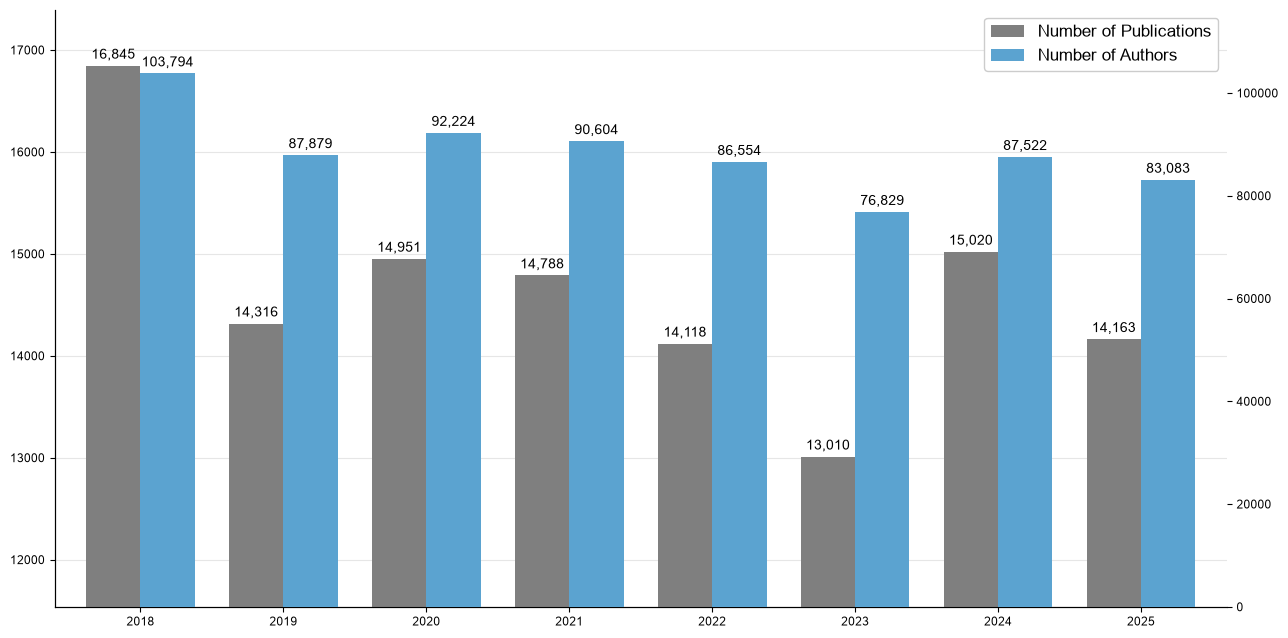

 year  publications  authors_distinct  author_paper_assignments  mean_team_size
 2018         16845          103794.0                    112160            6.66
 2019         14316           87879.0                     94262            6.58
 2020         14951           92224.0                     99358            6.65
 2021         14788           90604.0                     98419            6.66
 2022         14118           86554.0                     92920            6.58
 2023         13010           76829.0                     81776            6.29
 2024         15020           87522.0                     93470            6.22
 2025         14163           83083.0                     88284            6.23

-- Table A.1: papers by primary domain and year
    saved tableA1_domain_by_year.tex

-- Table A.2: papers by primary field and year
    saved tableA2_field_by_year.tex

-- Figure: team size over time


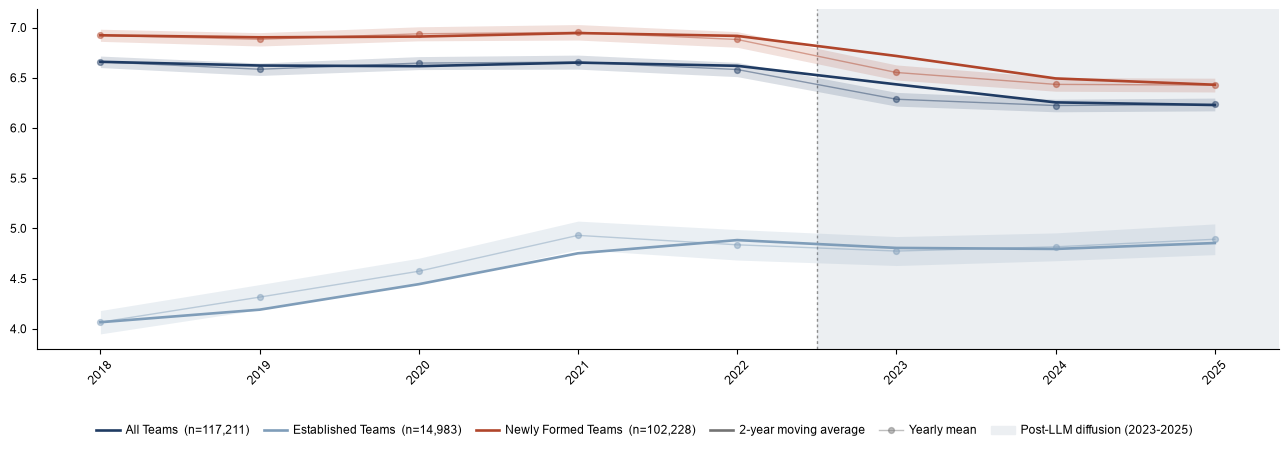

group_label  All Teams  Established Teams  Newly Formed Teams
year                                                         
2018             6.658              4.065               6.922
2019             6.584              4.315               6.882
2020             6.646              4.573               6.937
2021             6.655              4.930               6.952
2022             6.582              4.836               6.881
2023             6.286              4.774               6.552
2024             6.223              4.816               6.434
2025             6.233              4.891               6.427


seed_year,2018,2019,2020,2021,2022,2023,2024,2025,Total
paper_primary_domain,,,,,,,,,
Health Sciences,7260,6335,6680,6724,6348,5338,6049,5739,50473
Life Sciences,5299,4262,4058,3279,2949,2731,3076,2755,28409
Physical Sciences,2699,2175,2361,2445,2243,2250,3035,3206,20414
Social Sciences,1587,1544,1852,2340,2578,2691,2860,2463,17915
Total,16845,14316,14951,14788,14118,13010,15020,14163,117211


seed_year,2018,2019,2020,2021,2022,2023,2024,2025,Total
paper_primary_field,,,,,,,,,
Medicine,6505,5598,5830,5886,5477,4511,5091,4894,43792
"Biochemistry, Genetics and Molecular Biology",2581,2002,1841,1402,1372,1201,1395,1160,12954
Environmental Science,1255,1060,1037,964,819,756,983,901,7775
Agricultural and Biological Sciences,1319,1104,1128,974,783,742,836,821,7707
Psychology,657,628,739,940,908,882,847,783,6384
Social Sciences,568,506,634,804,949,885,962,864,6172
Engineering,502,381,441,487,473,563,862,1034,4743
Neuroscience,790,628,597,529,459,481,515,454,4453
Health Professions,399,404,489,490,536,515,610,551,3994


group_label,All Teams,Established Teams,Newly Formed Teams
year,,,
2018,6.658,4.065,6.922
2019,6.584,4.315,6.882
2020,6.646,4.573,6.937
2021,6.655,4.930,6.952
2022,6.582,4.836,6.881
2023,6.286,4.774,6.552
2024,6.223,4.816,6.434
2025,6.233,4.891,6.427


In [6]:
out1 = R.block1(d)  # Table 1   summary statistics

display(out1["tableA1"])       # Table A.1 papers by domain and year
display(out1["tableA2"])       # Table A.2 papers by field and year
out1["team_size"].pivot_table(index="year", columns="group_label",
                              values="mean").round(3)

In [7]:
display(out1["table1"])                                      # Table 1
display(out1["composition"].round(2))                        # Figure A.1, underlying
out1["team_size"].pivot_table(index="year", columns="group_label",
                              values="mean").round(3)

,Variable,All Teams Mean (SD),All Teams Share,Established Teams Mean (SD),Established Teams Share,Newly Formed Teams Mean (SD),Newly Formed Teams Share
0,Panel A: Pre-LLM Baseline Period (2018--2019),,,,,,
1,Task Participation Outcomes ($P_{kpt}$),,,,,,
2,Ideation,4.07 (2.59),0.665,3.09 (1.77),0.782,4.19 (2.65),0.652
3,Data and Coding,2.54 (2.54),0.399,1.74 (1.61),0.436,2.63 (2.61),0.395
4,Execution,4.37 (3.13),0.677,2.88 (1.99),0.711,4.54 (3.19),0.673
5,Writing,4.85 (3.20),0.778,3.59 (2.06),0.890,4.99 (3.28),0.766
6,Coordination,2.39 (2.03),0.394,1.94 (1.49),0.491,2.44 (2.07),0.383
7,Funding and Resources,1.94 (2.12),0.309,1.49 (1.61),0.369,1.99 (2.16),0.303
8,Portfolio Specialisation Outcomes,,,,,,
9,Tasks per Author,3.223 (0.968),--,3.679 (0.966),--,3.171 (0.955),--


,year,publications,authors_distinct,author_paper_assignments,mean_team_size
0,2018,16845,103794.0,112160,6.66
1,2019,14316,87879.0,94262,6.58
2,2020,14951,92224.0,99358,6.65
3,2021,14788,90604.0,98419,6.66
4,2022,14118,86554.0,92920,6.58
5,2023,13010,76829.0,81776,6.29
6,2024,15020,87522.0,93470,6.22
7,2025,14163,83083.0,88284,6.23


group_label,All Teams,Established Teams,Newly Formed Teams
year,,,
2018,6.658,4.065,6.922
2019,6.584,4.315,6.882
2020,6.646,4.573,6.937
2021,6.655,4.930,6.952
2022,6.582,4.836,6.881
2023,6.286,4.774,6.552
2024,6.223,4.816,6.434
2025,6.233,4.891,6.427


## Block 2 — H1 task participation and H2 portfolio specialisation

All teams. Contributor shares and counts across the six task domains,
then the two specialisation metrics; levels and detrended for each.
Table B.1 is the static baseline.


BLOCK 2  H1 task participation and H2 portfolio specialisation

-- H1 Contributor share, all teams

  SPEC [share]  y ~ i(year, ref=2022) + log(team size) + log(IIC + 1) + log(prior publications per author + 1) + log(academic age + 1) | paper_primary_field
        pyfixest, HC1; pre-trend on [2018, 2019, 2020, 2021], break on [2023, 2024, 2025]

     Ideation                   pre p=0.738  post p<0.001***  break p<0.001***  N 117,211
     Data and Coding            pre p<0.001***  post p<0.001***  break p<0.001***  N 117,211
     Execution                  pre p=0.019*  post p<0.001***  break p=0.002**  N 117,211
     Writing                    pre p<0.001***  post p<0.001***  break p<0.001***  N 117,211
     Coordination               pre p=0.514  post p<0.001***  break p=0.044*  N 117,211
     Funding and Resources      pre p<0.001***  post p=0.307  break p<0.001***  N 117,211


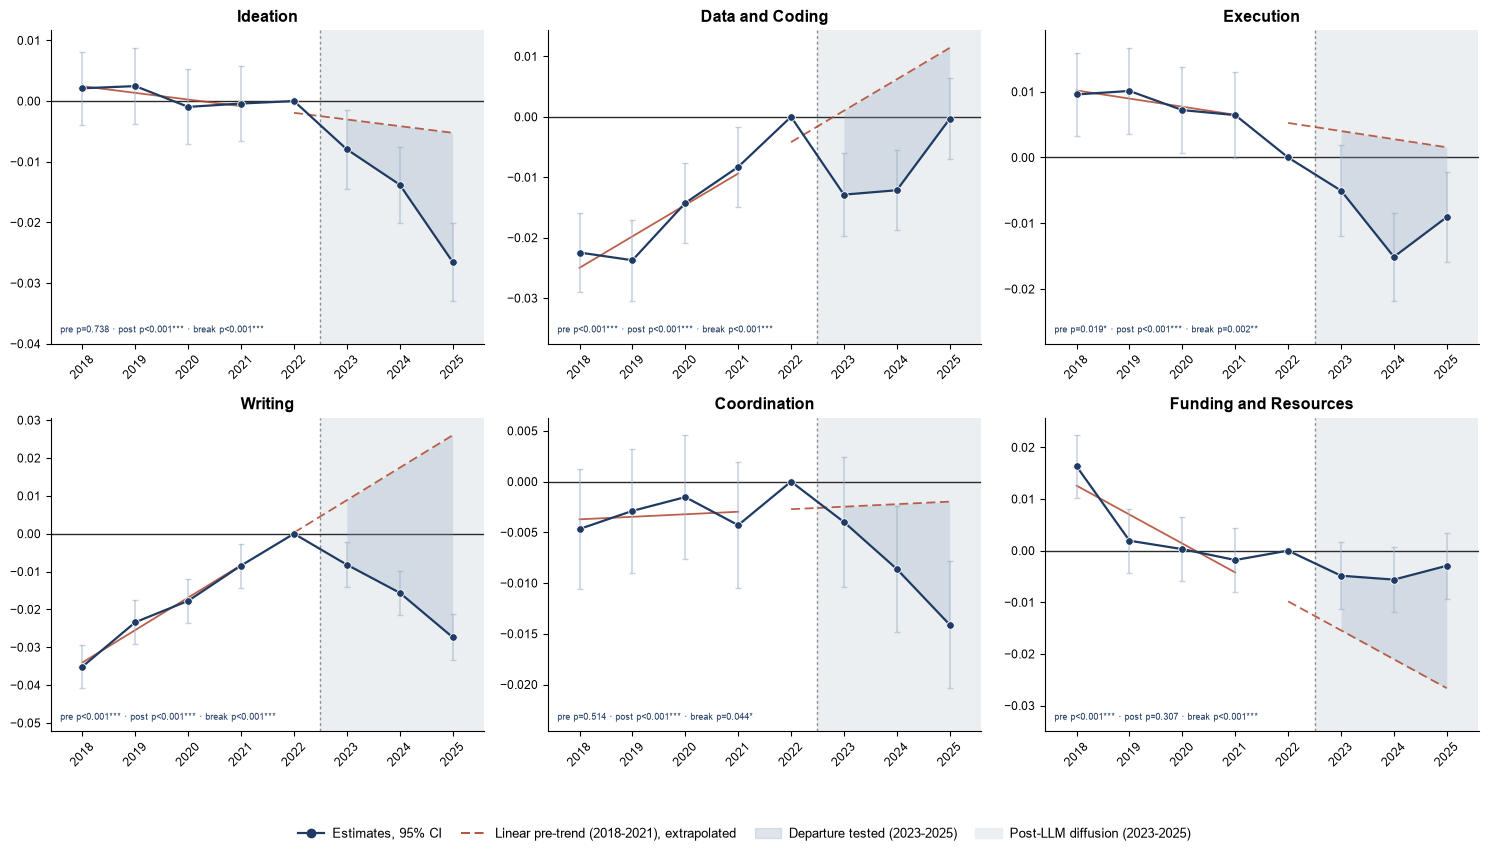

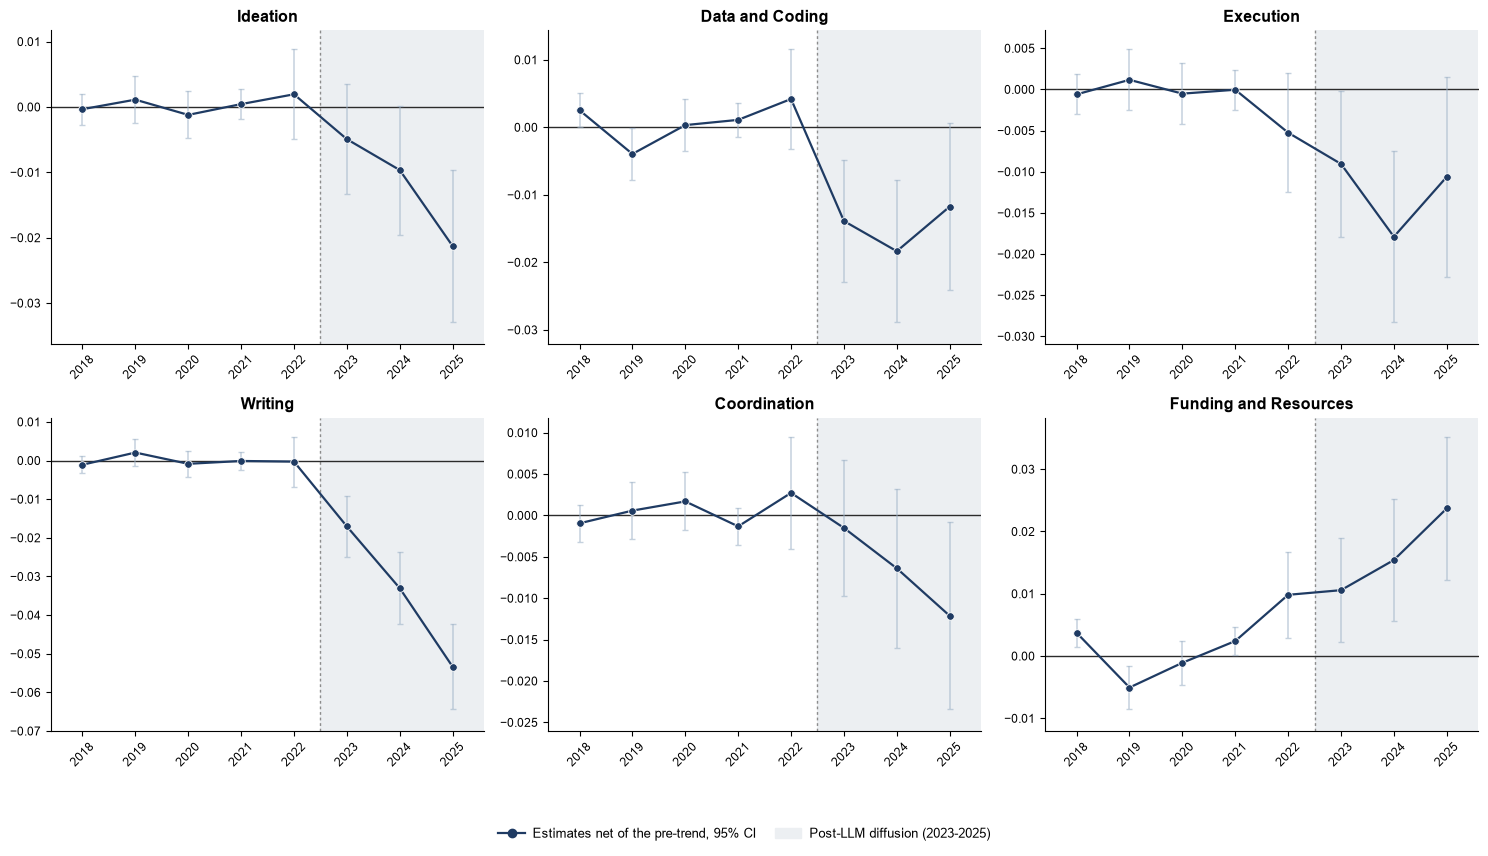


-- H1 Log contributor count, all teams

  SPEC [count]  y ~ i(year, ref=2022) + log(team size) + log(IIC + 1) + log(prior publications per author + 1) + log(academic age + 1) | paper_primary_field
        pyfixest, HC1; pre-trend on [2018, 2019, 2020, 2021], break on [2023, 2024, 2025]

     Ideation                   pre p=0.790  post p<0.001***  break p<0.001***  N 117,211
     Data and Coding            pre p<0.001***  post p<0.001***  break p<0.001***  N 117,211
     Execution                  pre p<0.001***  post p<0.001***  break p=0.001**  N 117,211
     Writing                    pre p<0.001***  post p<0.001***  break p<0.001***  N 117,211
     Coordination               pre p=0.647  post p<0.001***  break p=0.146  N 117,211
     Funding and Resources      pre p<0.001***  post p=0.653  break p<0.001***  N 117,211


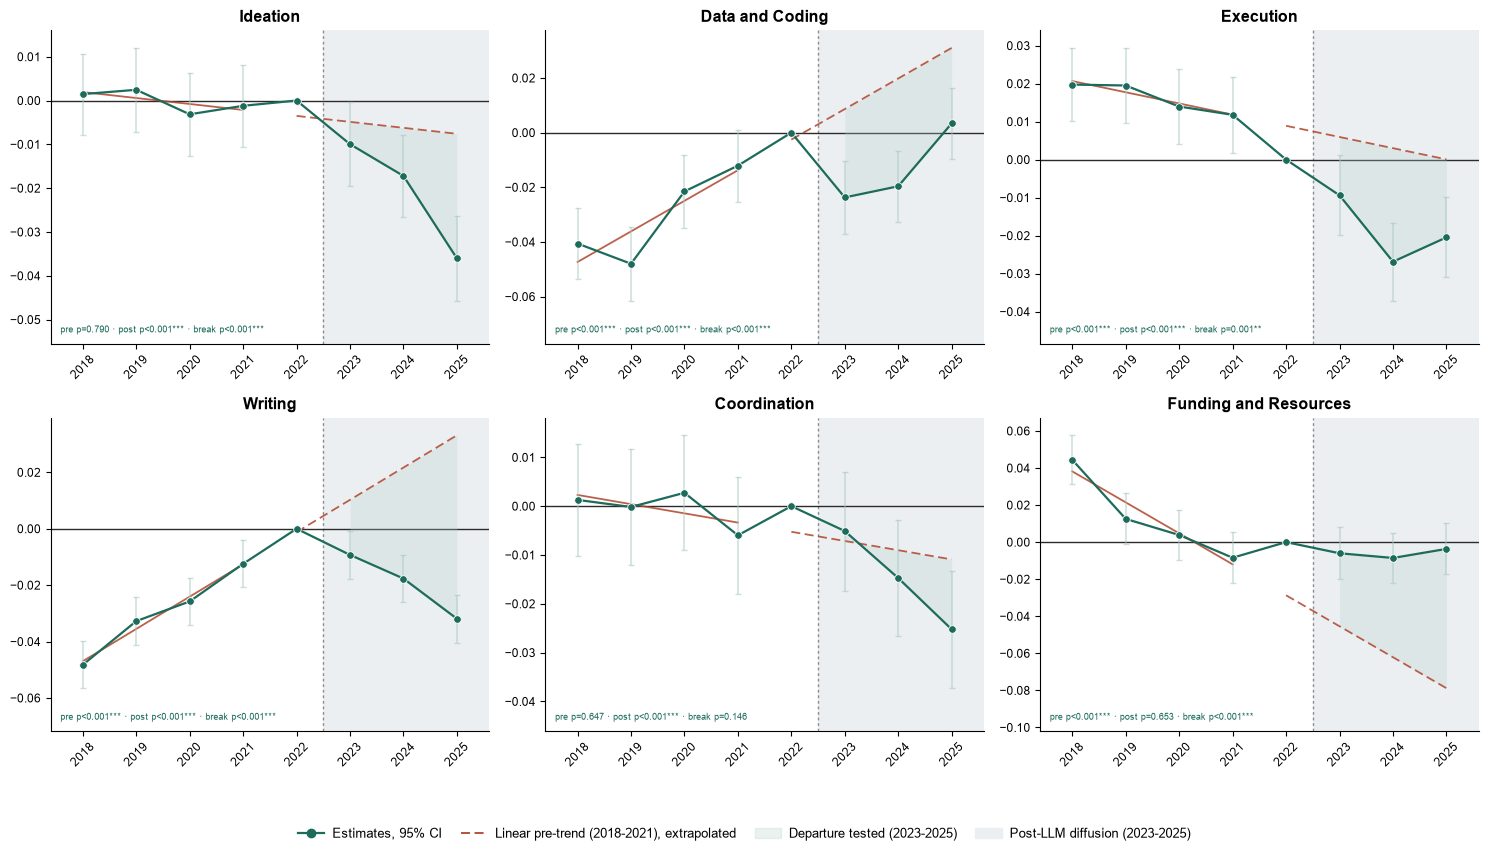

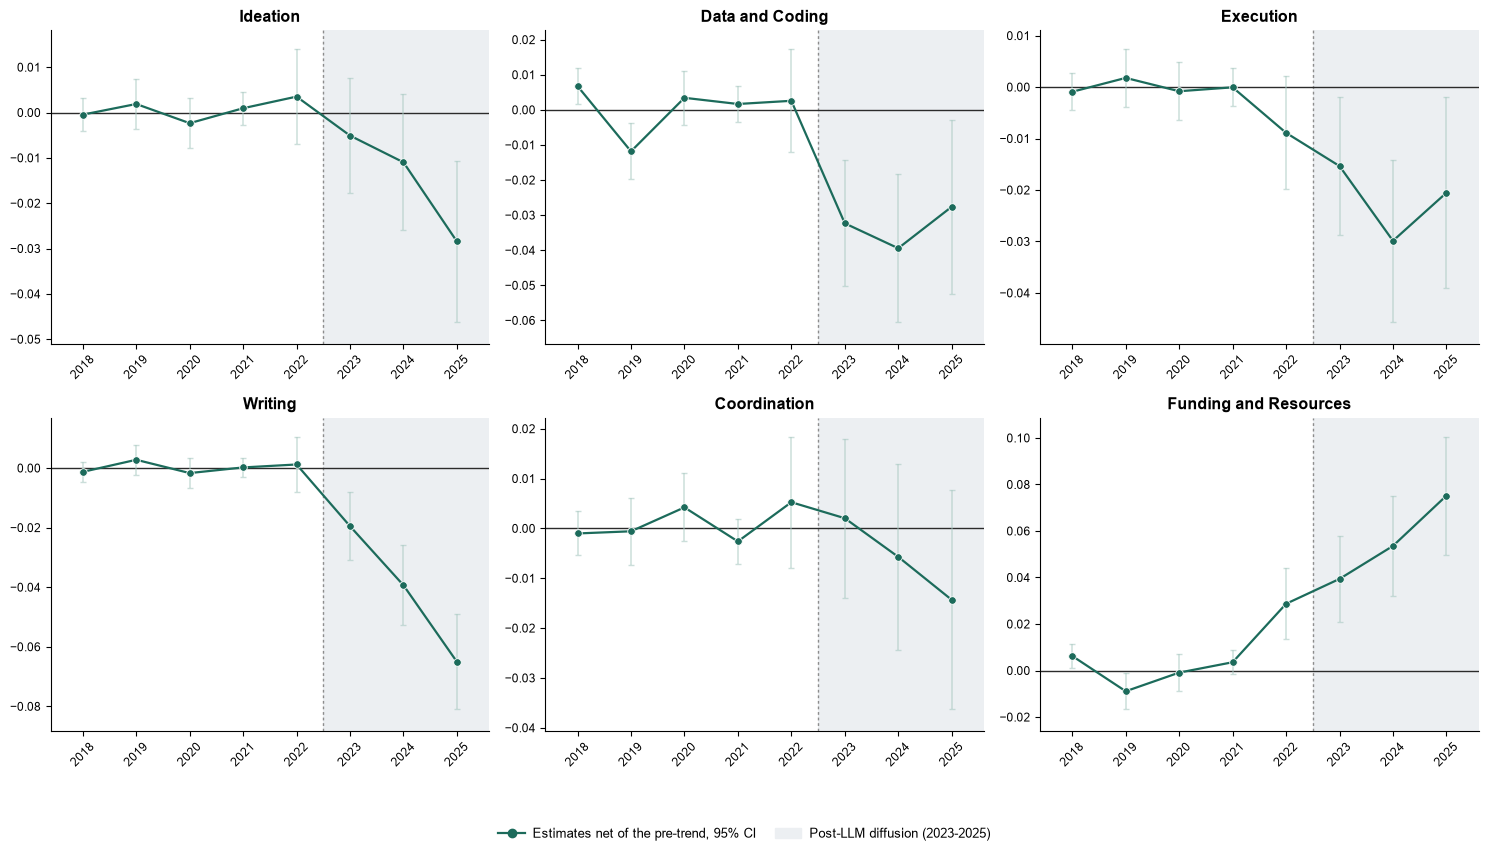


-- H2 portfolio specialisation, all teams

  SPEC [metric]  y ~ i(year, ref=2022) + log(team size) + log(IIC + 1) + log(prior publications per author + 1) + log(academic age + 1) | paper_primary_field
        pyfixest, HC1; pre-trend on [2018, 2019, 2020, 2021], break on [2023, 2024, 2025]

     Tasks per Author           pre p=0.004**  post p<0.001***  break p<0.001***  N 117,211
     Task Overlap               pre p<0.001***  post p<0.001***  break p<0.001***  N 117,211


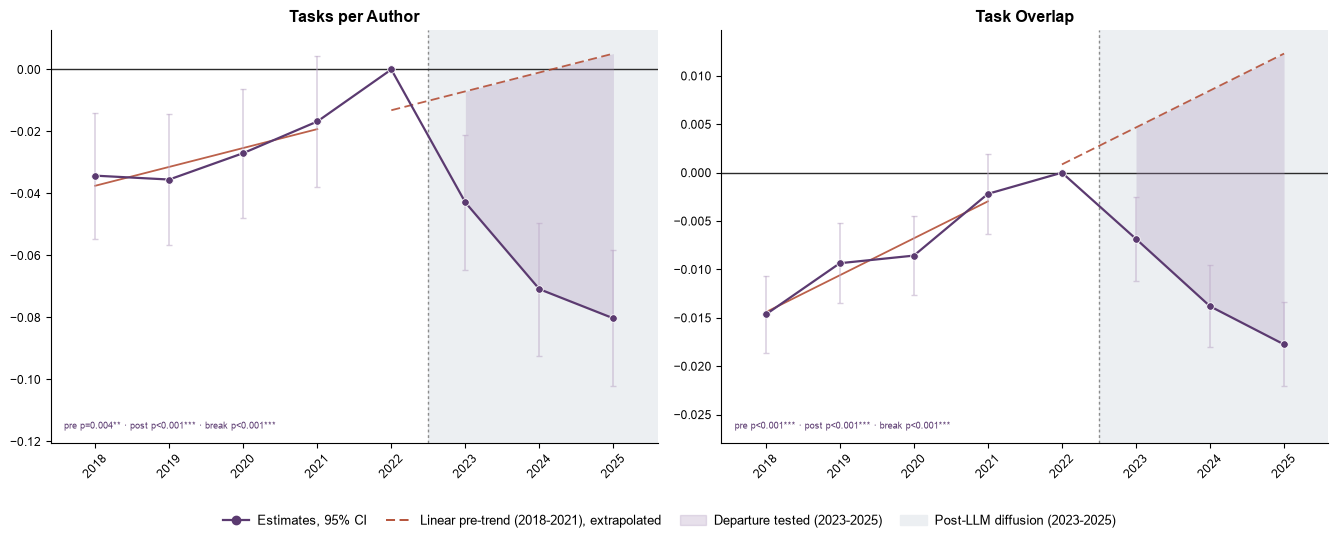

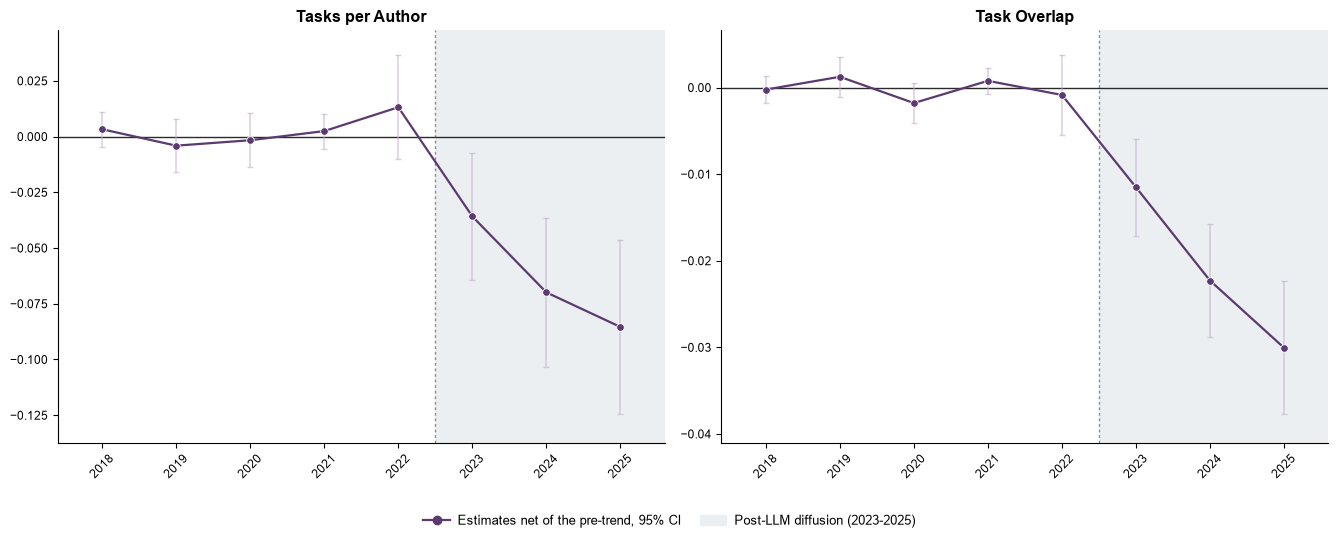


-- Table B.1: static post-LLM estimates by task domain
    saved tableB1_static_by_stage.tex
                              sample outcome             stage                 label term    beta     se      p mark      N     r2
            Full Period (2018--2025)   share          ideation              Ideation post -0.0169 0.0017 0.0000  *** 117211 0.1240
            Full Period (2018--2025)   share   data_and_coding       Data and Coding post  0.0054 0.0018 0.0022   ** 117211 0.0375
            Full Period (2018--2025)   share         execution             Execution post -0.0167 0.0018 0.0000  *** 117211 0.0348
            Full Period (2018--2025)   share     communication               Writing post  0.0000 0.0016 0.9957      117211 0.1322
            Full Period (2018--2025)   share      coordination          Coordination post -0.0063 0.0016 0.0001  *** 117211 0.0769
            Full Period (2018--2025)   share funding_resources Funding and Resources post -0.0081 0.0017 0.0000  *** 117

In [8]:
out2 = R.block2(d, controls)

In [9]:
display(out2["tableB1"].round(4))                            # Table B.1

# any single event study is inspectable on its own. The results dicts are
# keyed by (kind, key).
es = out2["H1"]["share"][("share", "ideation")]
print(f"{es.label}:  pre p={es.pre_p:.3g}   post p={es.post_p:.3g}   "
      f"break p={es.break_p:.3g}   N={es.n:,}")
es.coefs.round(4)              # year, estimate, low, high

,sample,outcome,stage,label,term,beta,se,p,mark,N,r2
0,Full Period (2018--2025),share,ideation,Ideation,post,-0.0169,0.0017,0.0000,***,117211,0.1240
1,Full Period (2018--2025),share,data_and_coding,Data and Coding,post,0.0054,0.0018,0.0022,**,117211,0.0375
2,Full Period (2018--2025),share,execution,Execution,post,-0.0167,0.0018,0.0000,***,117211,0.0348
3,Full Period (2018--2025),share,communication,Writing,post,0.0000,0.0016,0.9957,,117211,0.1322
4,Full Period (2018--2025),share,coordination,Coordination,post,-0.0063,0.0016,0.0001,***,117211,0.0769
5,Full Period (2018--2025),share,funding_resources,Funding and Resources,post,-0.0081,0.0017,0.0000,***,117211,0.0335
6,Full Period (2018--2025),count,ideation,Ideation,post,-0.0212,0.0025,0.0000,***,117211,0.3278
7,Full Period (2018--2025),count,data_and_coding,Data and Coding,post,0.0113,0.0035,0.0012,**,117211,0.1676
8,Full Period (2018--2025),count,execution,Execution,post,-0.0324,0.0028,0.0000,***,117211,0.4031
9,Full Period (2018--2025),count,communication,Writing,post,0.0044,0.0022,0.0488,*,117211,0.4663


Ideation:  pre p=0.738   post p=6.7e-15   break p=0.000174   N=117,211


,year,estimate,low,high
0,2018,0.0021,-0.0040,0.0082
1,2019,0.0025,-0.0038,0.0088
2,2020,-0.0010,-0.0072,0.0052
3,2021,-0.0004,-0.0066,0.0058
4,2022,0.0000,0.0000,0.0000
5,2023,-0.0080,-0.0144,-0.0015
6,2024,-0.0138,-0.0201,-0.0075
7,2025,-0.0265,-0.0329,-0.0201


## Block 3 — H3 team history

The same outcomes estimated separately for established and newly formed
teams, plus the interaction tables B.2 and B.3.


BLOCK 3  H3 team history and the reallocation of participation

########## Established Teams  (n=14,983) ##########

-- Contributor share
     Ideation                   pre p=0.099†  post p=0.231  break p=0.161  N 14,983
     Data and Coding            pre p<0.001***  post p=0.045*  break p=0.347  N 14,983
     Execution                  pre p=0.869  post p=0.362  break p=0.409  N 14,983
     Writing                    pre p=0.276  post p=0.507  break p=0.143  N 14,983
     Coordination               pre p=0.202  post p=0.594  break p=0.072†  N 14,983
     Funding and Resources      pre p<0.001***  post p=0.042*  break p=0.803  N 14,983

-- Log contributor count
     Ideation                   pre p=0.083†  post p=0.300  break p=0.178  N 14,983
     Data and Coding            pre p<0.001***  post p=0.017*  break p=0.276  N 14,983
     Execution                  pre p=0.744  post p=0.510  break p=0.624  N 14,983
     Writing                    pre p=0.210  post p=0.713  break p=0.146 

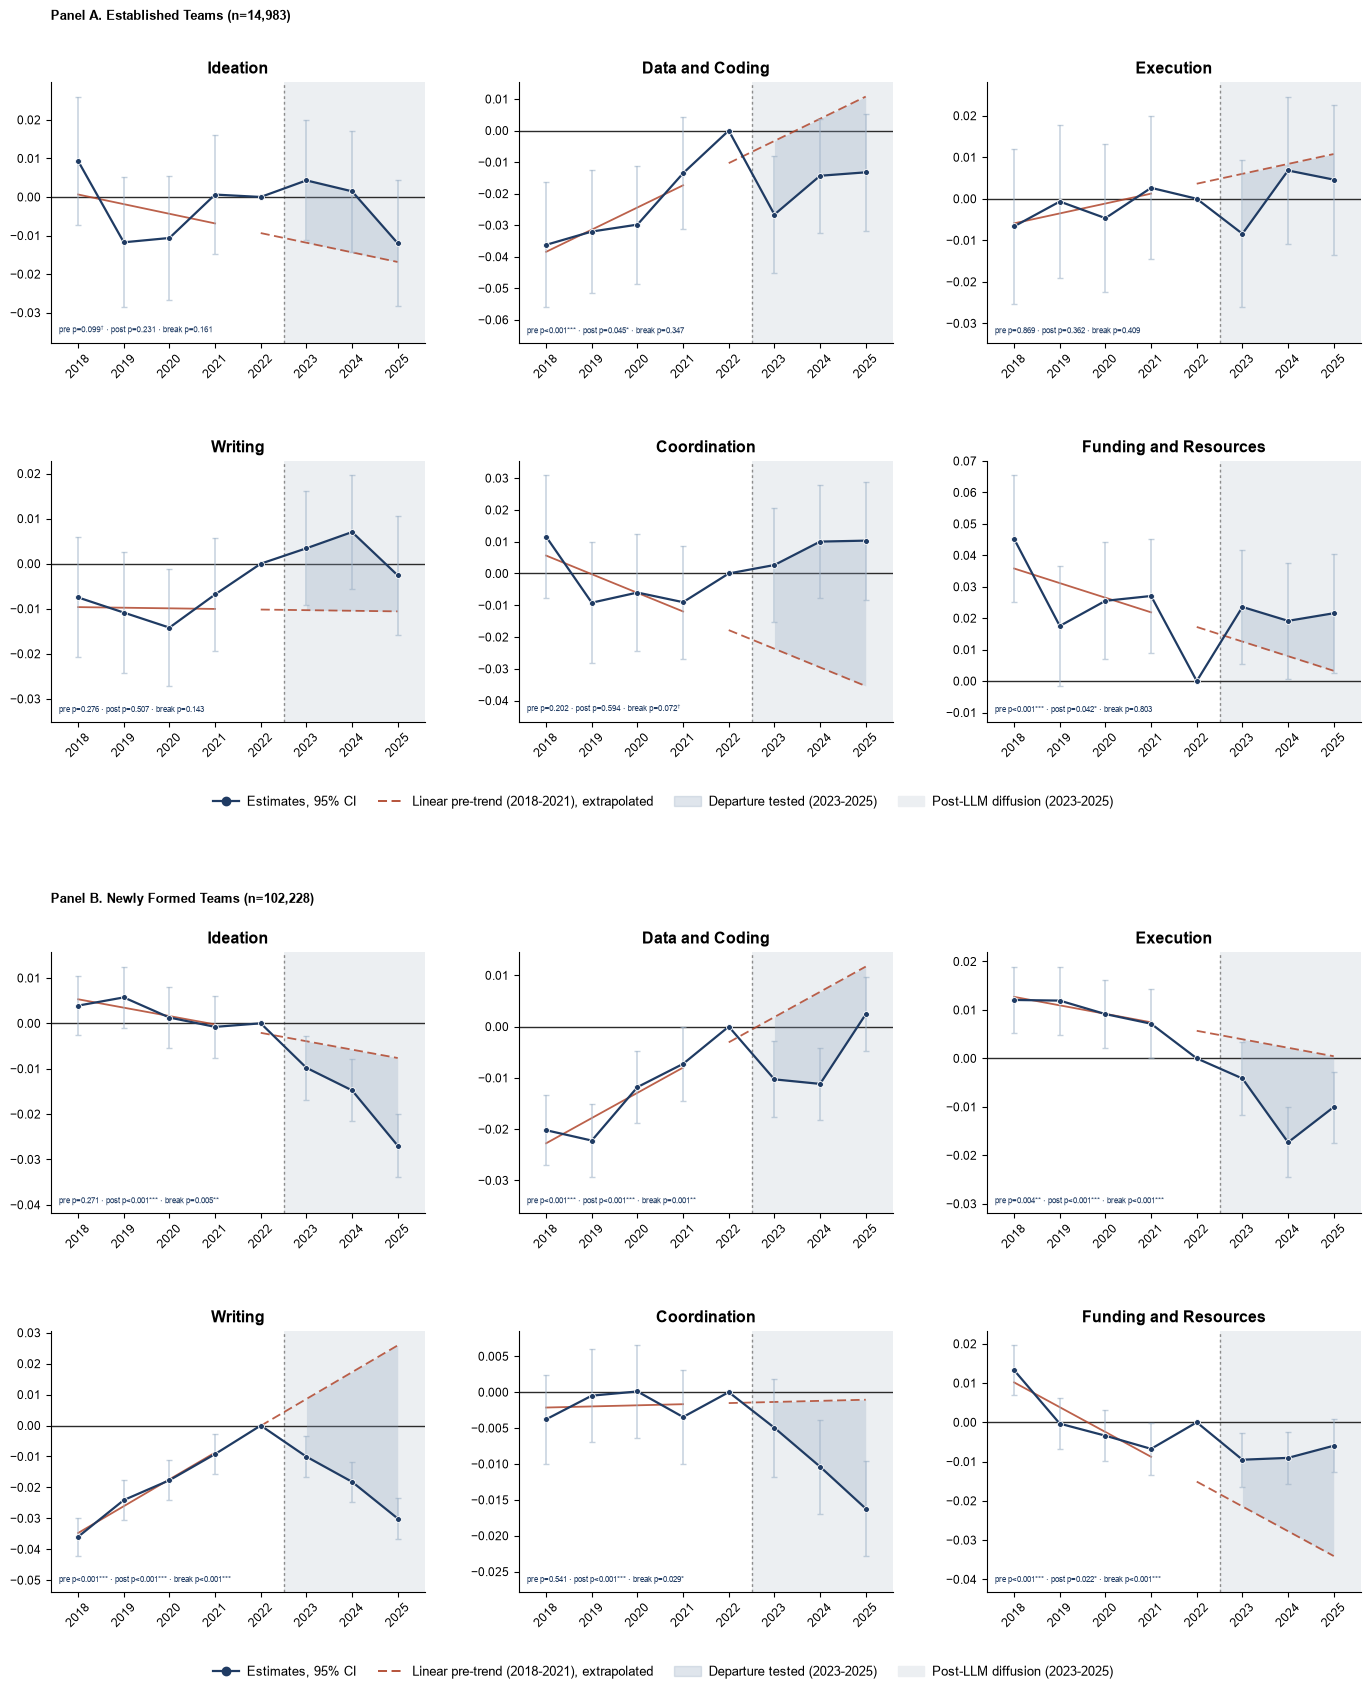

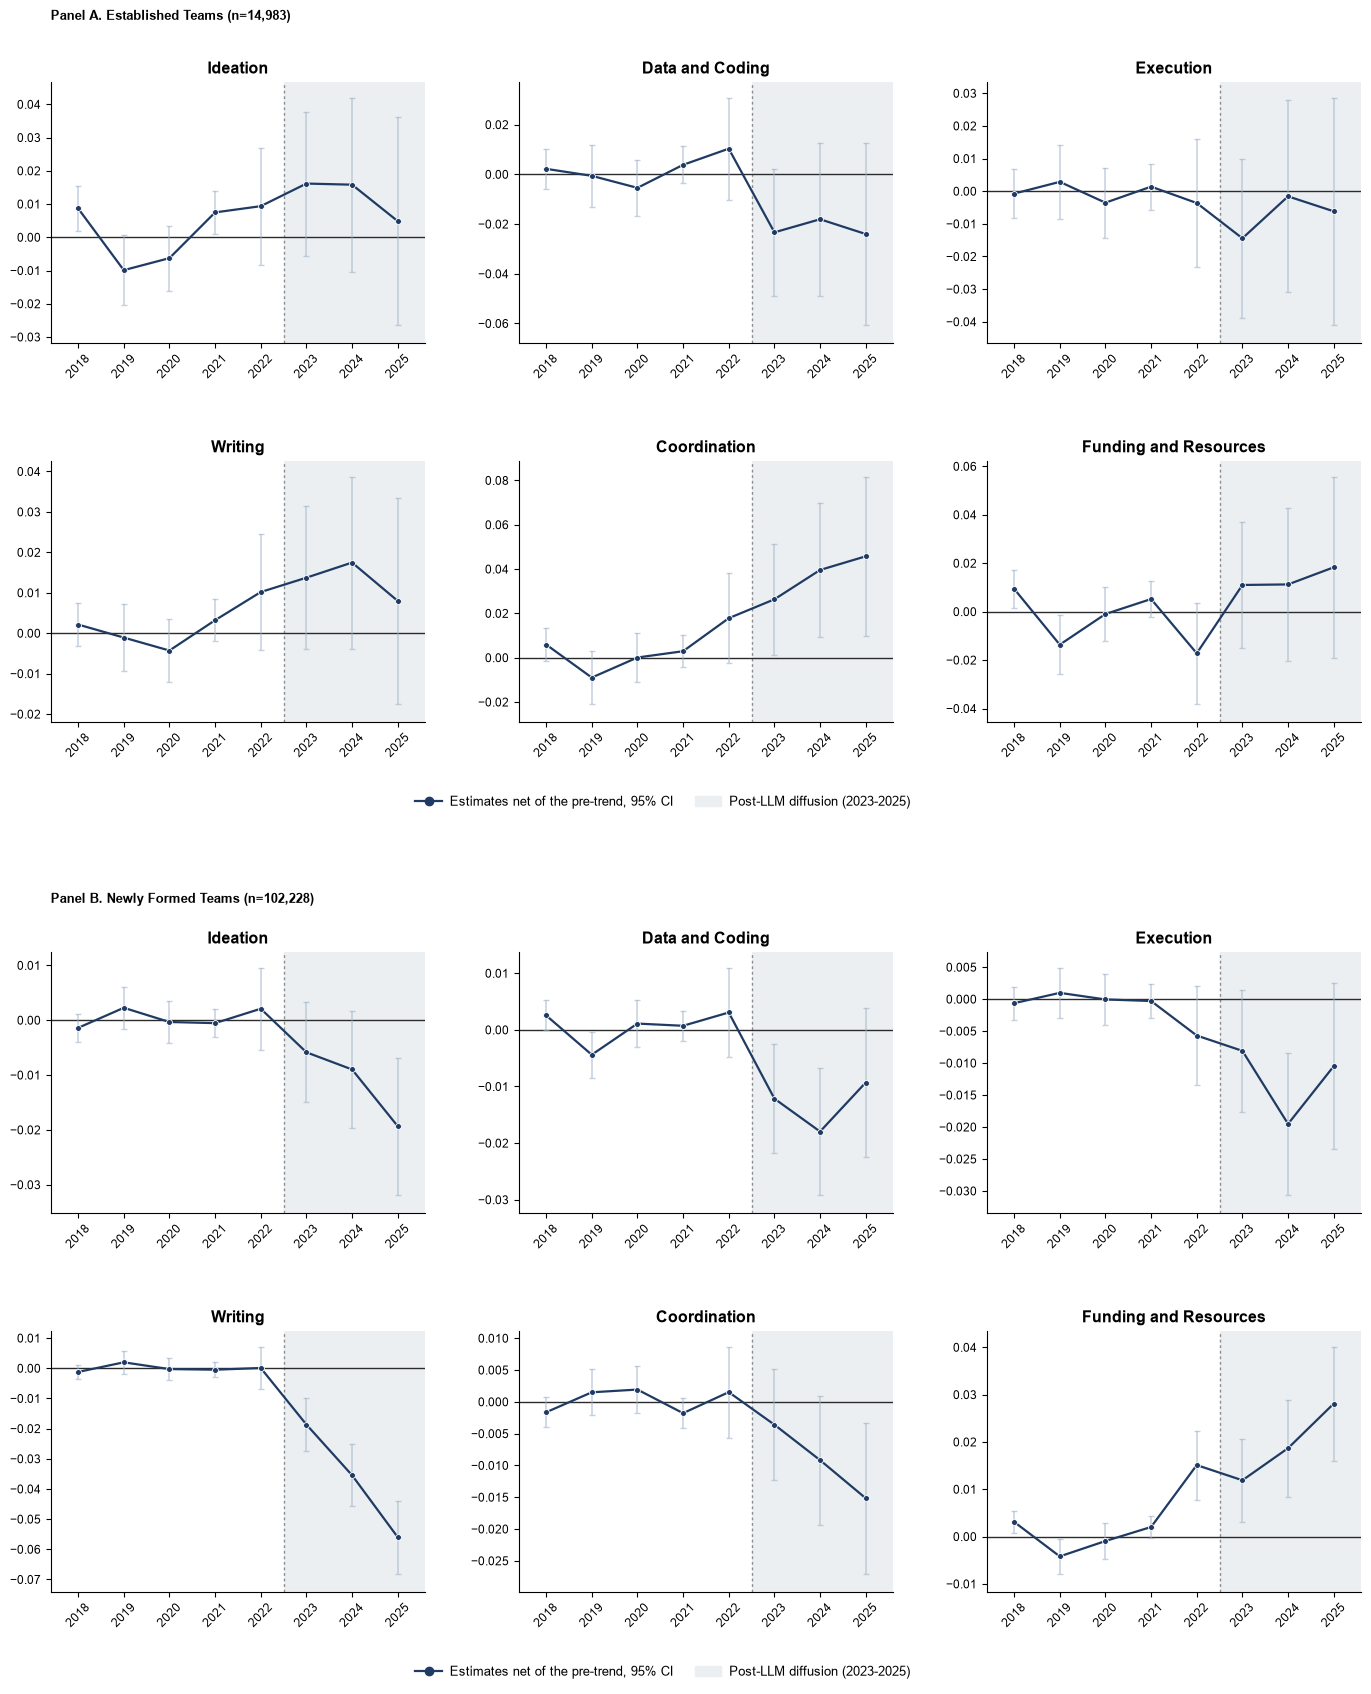

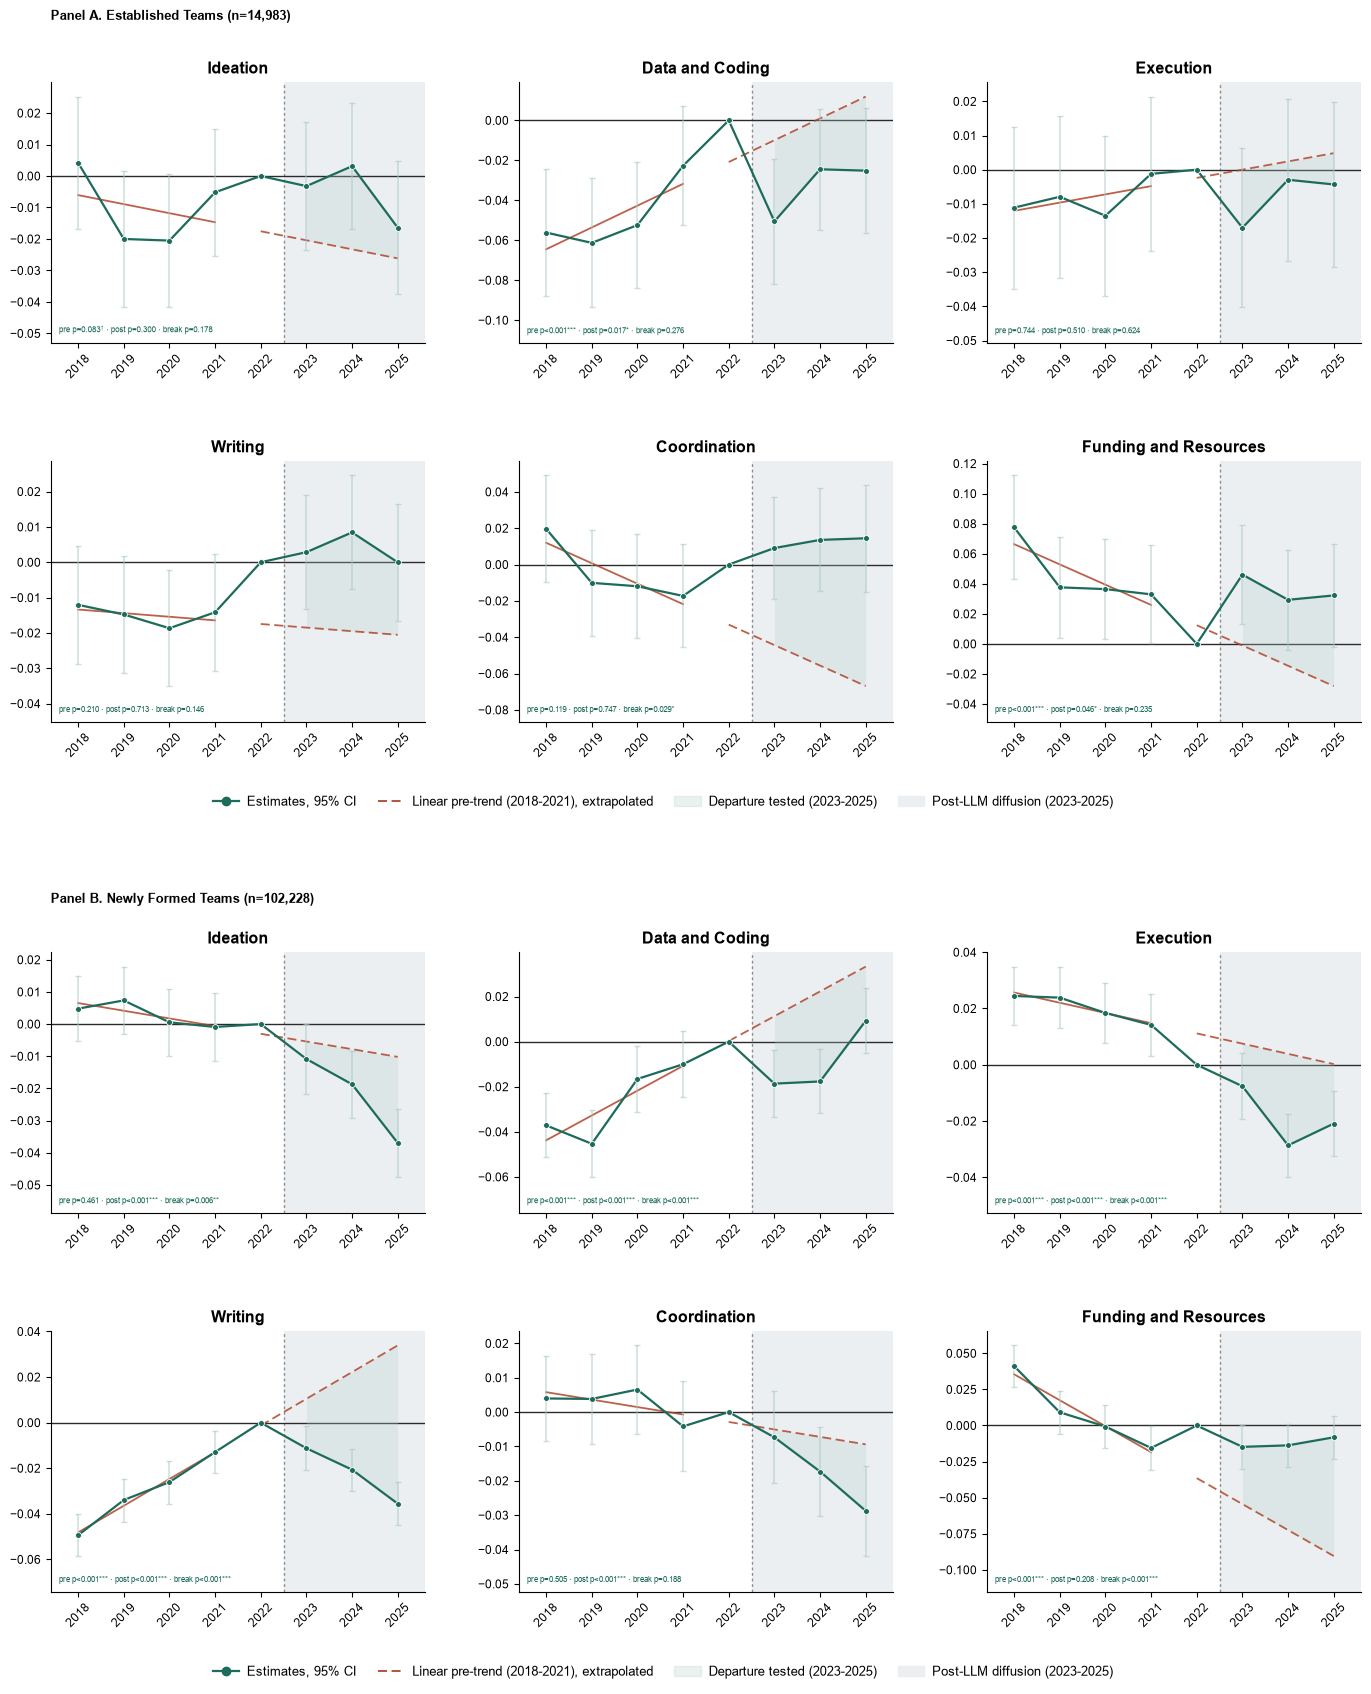

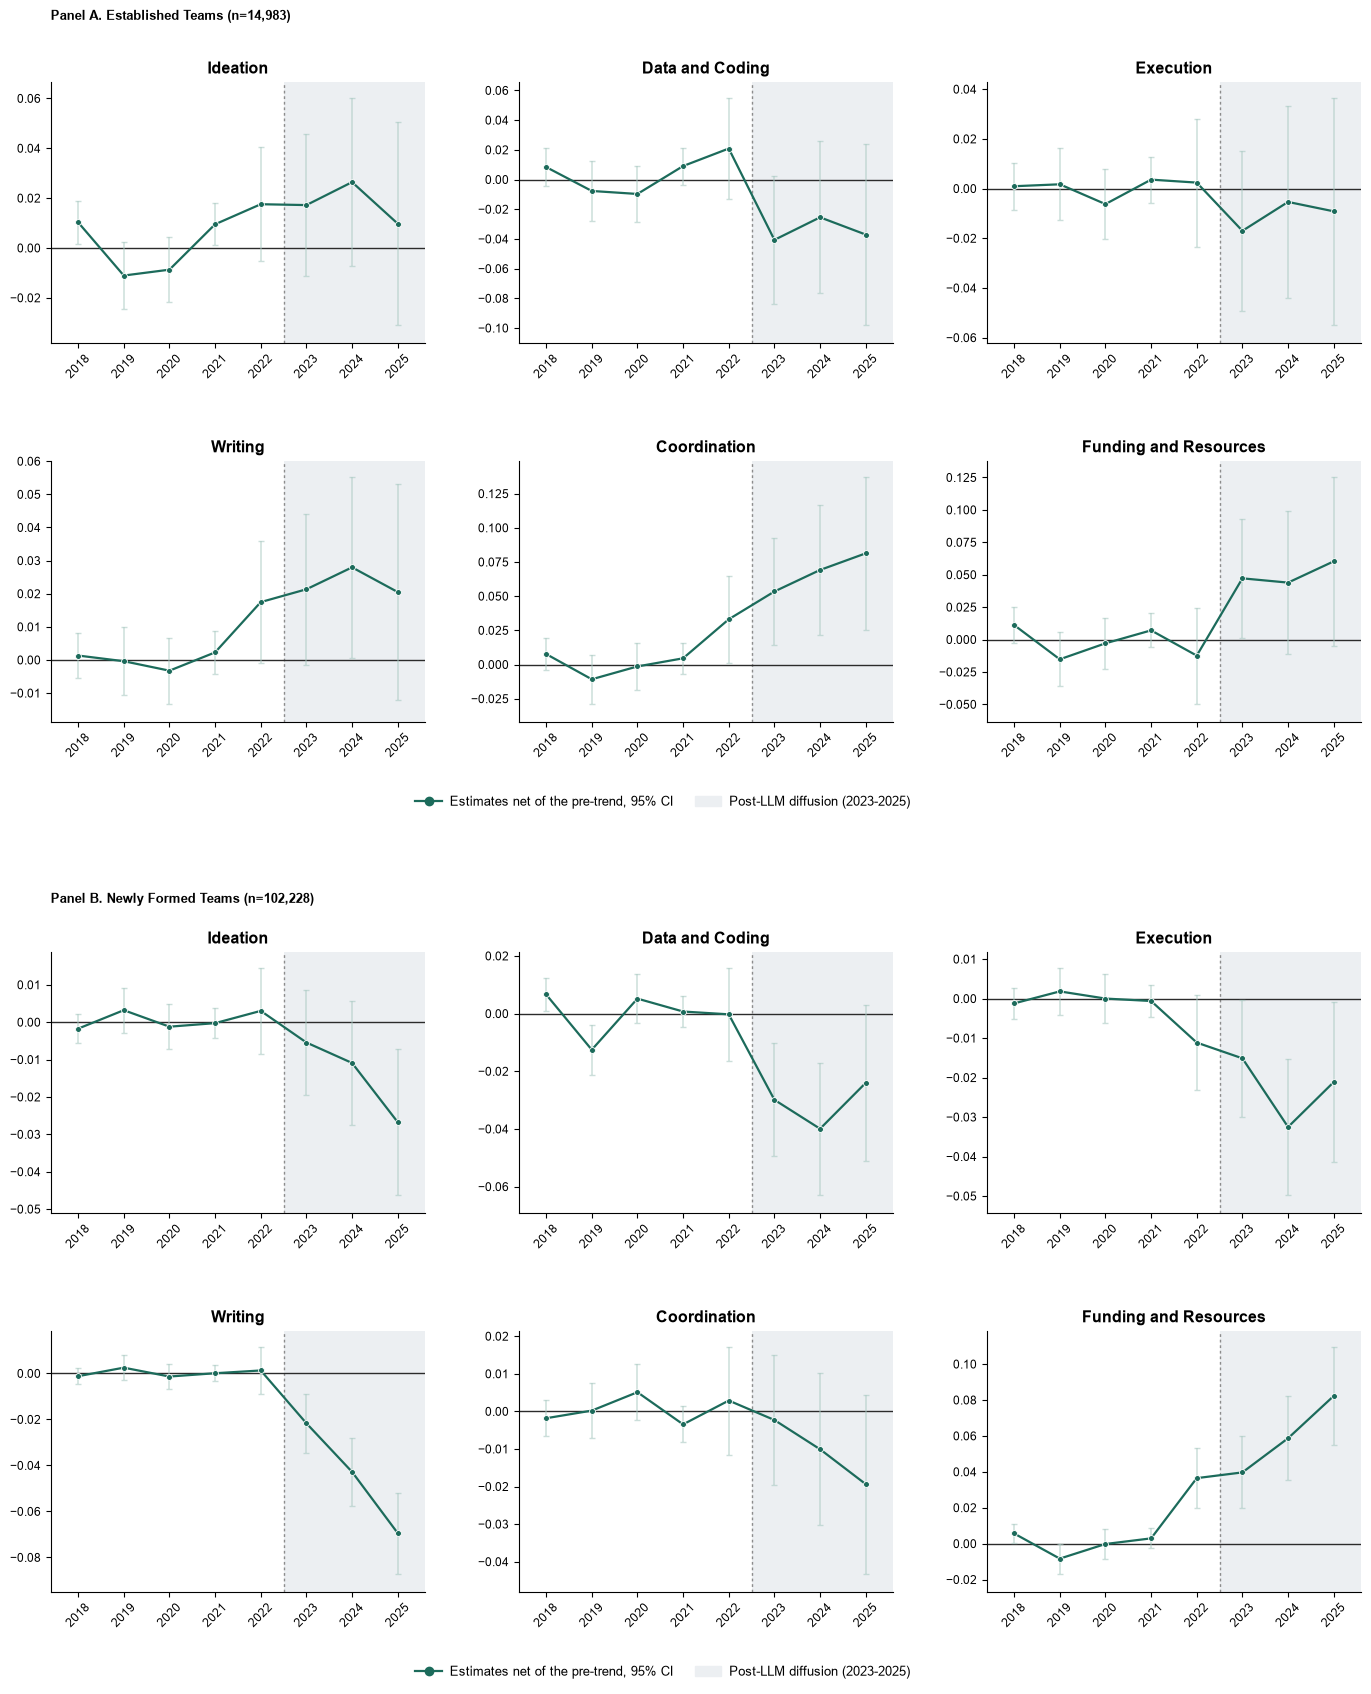

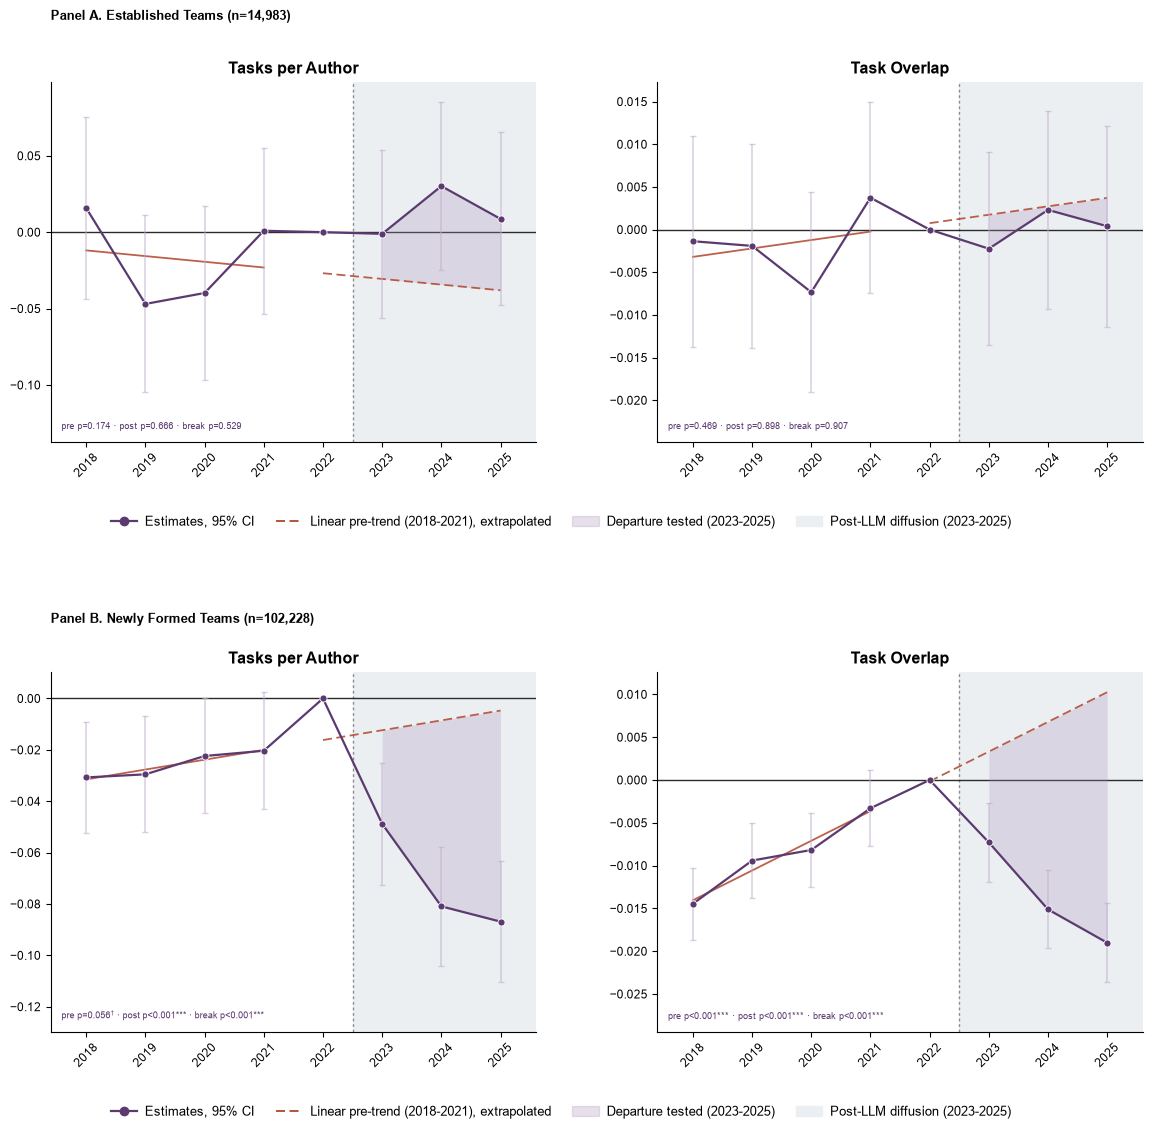

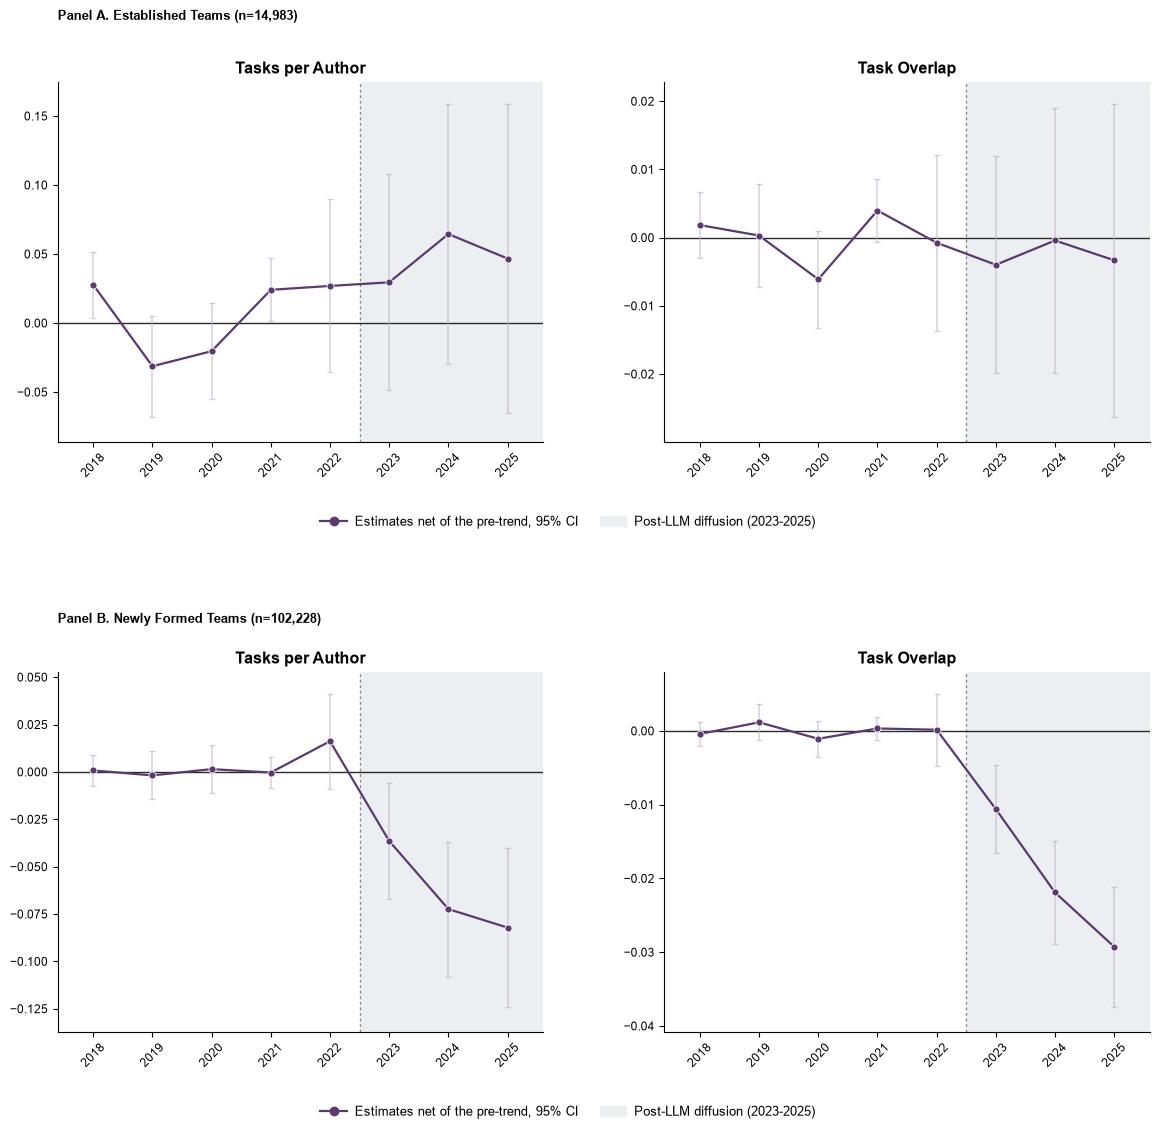


-- Table B.2: participation, Post x New
    saved tableB2_participation_interactions.tex
                              sample outcome             stage                 label     term    beta     se      p mark      N     r2
            Full Period (2018--2025)   share          ideation              Ideation     post  0.0012 0.0043 0.7881      117211 0.1274
            Full Period (2018--2025)   share          ideation              Ideation      new -0.0435 0.0030 0.0000  *** 117211 0.1274
            Full Period (2018--2025)   share          ideation              Ideation post_new -0.0212 0.0047 0.0000  *** 117211 0.1274
            Full Period (2018--2025)   share   data_and_coding       Data and Coding     post  0.0023 0.0050 0.6481      117211 0.0377
            Full Period (2018--2025)   share   data_and_coding       Data and Coding      new -0.0140 0.0034 0.0000  *** 117211 0.0377
            Full Period (2018--2025)   share   data_and_coding       Data and Coding post_new  0.003

In [19]:
out3 = R.block3(d, controls)

In [20]:
display(out3["tableB2"].round(4))                            # Table B.2
display(out3["tableB3"].round(4))                            # Table B.3

,sample,outcome,stage,label,term,beta,se,p,mark,N,r2
0,Full Period (2018--2025),share,ideation,Ideation,post,0.0012,0.0043,0.7881,,117211,0.1274
1,Full Period (2018--2025),share,ideation,Ideation,new,-0.0435,0.0030,0.0000,***,117211,0.1274
2,Full Period (2018--2025),share,ideation,Ideation,post_new,-0.0212,0.0047,0.0000,***,117211,0.1274
3,Full Period (2018--2025),share,data_and_coding,Data and Coding,post,0.0023,0.0050,0.6481,,117211,0.0377
4,Full Period (2018--2025),share,data_and_coding,Data and Coding,new,-0.0140,0.0034,0.0000,***,117211,0.0377
...,...,...,...,...,...,...,...,...,...,...,...
67,No Contamination (2018--19/2024--25),count,coordination,Coordination,new,-0.0703,0.0086,0.0000,***,60344,0.1730
68,No Contamination (2018--19/2024--25),count,coordination,Coordination,post_new,-0.0353,0.0117,0.0026,**,60344,0.1730
69,No Contamination (2018--19/2024--25),count,funding_resources,Funding and Resources,post,-0.0302,0.0127,0.0172,*,60344,0.1313
70,No Contamination (2018--19/2024--25),count,funding_resources,Funding and Resources,new,-0.0442,0.0101,0.0000,***,60344,0.1313


,sample,metric,label,term,beta,se,p,mark,N,r2
0,Full Period (2018--2025),avg_tasks_per_author,Tasks per Author,post,0.0247,0.0152,0.1044,,117211,0.1558
1,Full Period (2018--2025),avg_tasks_per_author,Tasks per Author,new,-0.1769,0.0103,0.0000,***,117211,0.1558
2,Full Period (2018--2025),avg_tasks_per_author,Tasks per Author,post_new,-0.0791,0.0163,0.0000,***,117211,0.1558
3,Full Period (2018--2025),avg_jaccard,Task Overlap,post,0.0016,0.0031,0.6054,,117211,0.0512
4,Full Period (2018--2025),avg_jaccard,Task Overlap,new,-0.0404,0.0021,0.0000,***,117211,0.0512
5,Full Period (2018--2025),avg_jaccard,Task Overlap,post_new,-0.0090,0.0034,0.0074,**,117211,0.0512
6,No Contamination (2018--19/2024--25),avg_tasks_per_author,Tasks per Author,post,0.0328,0.0218,0.1322,,60344,0.1514
7,No Contamination (2018--19/2024--25),avg_tasks_per_author,Tasks per Author,new,-0.1885,0.0173,0.0000,***,60344,0.1514
8,No Contamination (2018--19/2024--25),avg_tasks_per_author,Tasks per Author,post_new,-0.0868,0.0232,0.0002,***,60344,0.1514
9,No Contamination (2018--19/2024--25),avg_jaccard,Task Overlap,post,0.0039,0.0045,0.3888,,60344,0.0511


## Block 4 — the 14 CRediT roles

Panel A the 14 roles, Panel B the two metrics computed over roles rather
than domains. All teams, then established, then newly formed.


BLOCK 4  the 14 CRediT contributor roles

########## All Teams  (n=117,211) ##########

-- Panel A: the 14 roles, contributor share

  SPEC [share14]  y ~ i(year, ref=2022) + log(team size) + log(IIC + 1) + log(prior publications per author + 1) + log(academic age + 1) | paper_primary_field
        pyfixest, HC1; pre-trend on [2018, 2019, 2020, 2021], break on [2023, 2024, 2025]

     Conceptualization          pre p=0.109  post p<0.001***  break p<0.001***  N 117,211
     Methodology                pre p=0.420  post p<0.001***  break p<0.001***  N 117,211
     Software                   pre p<0.001***  post p<0.001***  break p=0.002**  N 117,211
     Validation                 pre p<0.001***  post p<0.001***  break p=0.024*  N 117,211
     Formal Analysis            pre p=0.020*  post p<0.001***  break p<0.001***  N 117,211
     Investigation              pre p<0.001***  post p<0.001***  break p=0.193  N 117,211
     Resources                  pre p<0.001***  post p=0.039*  break p<0

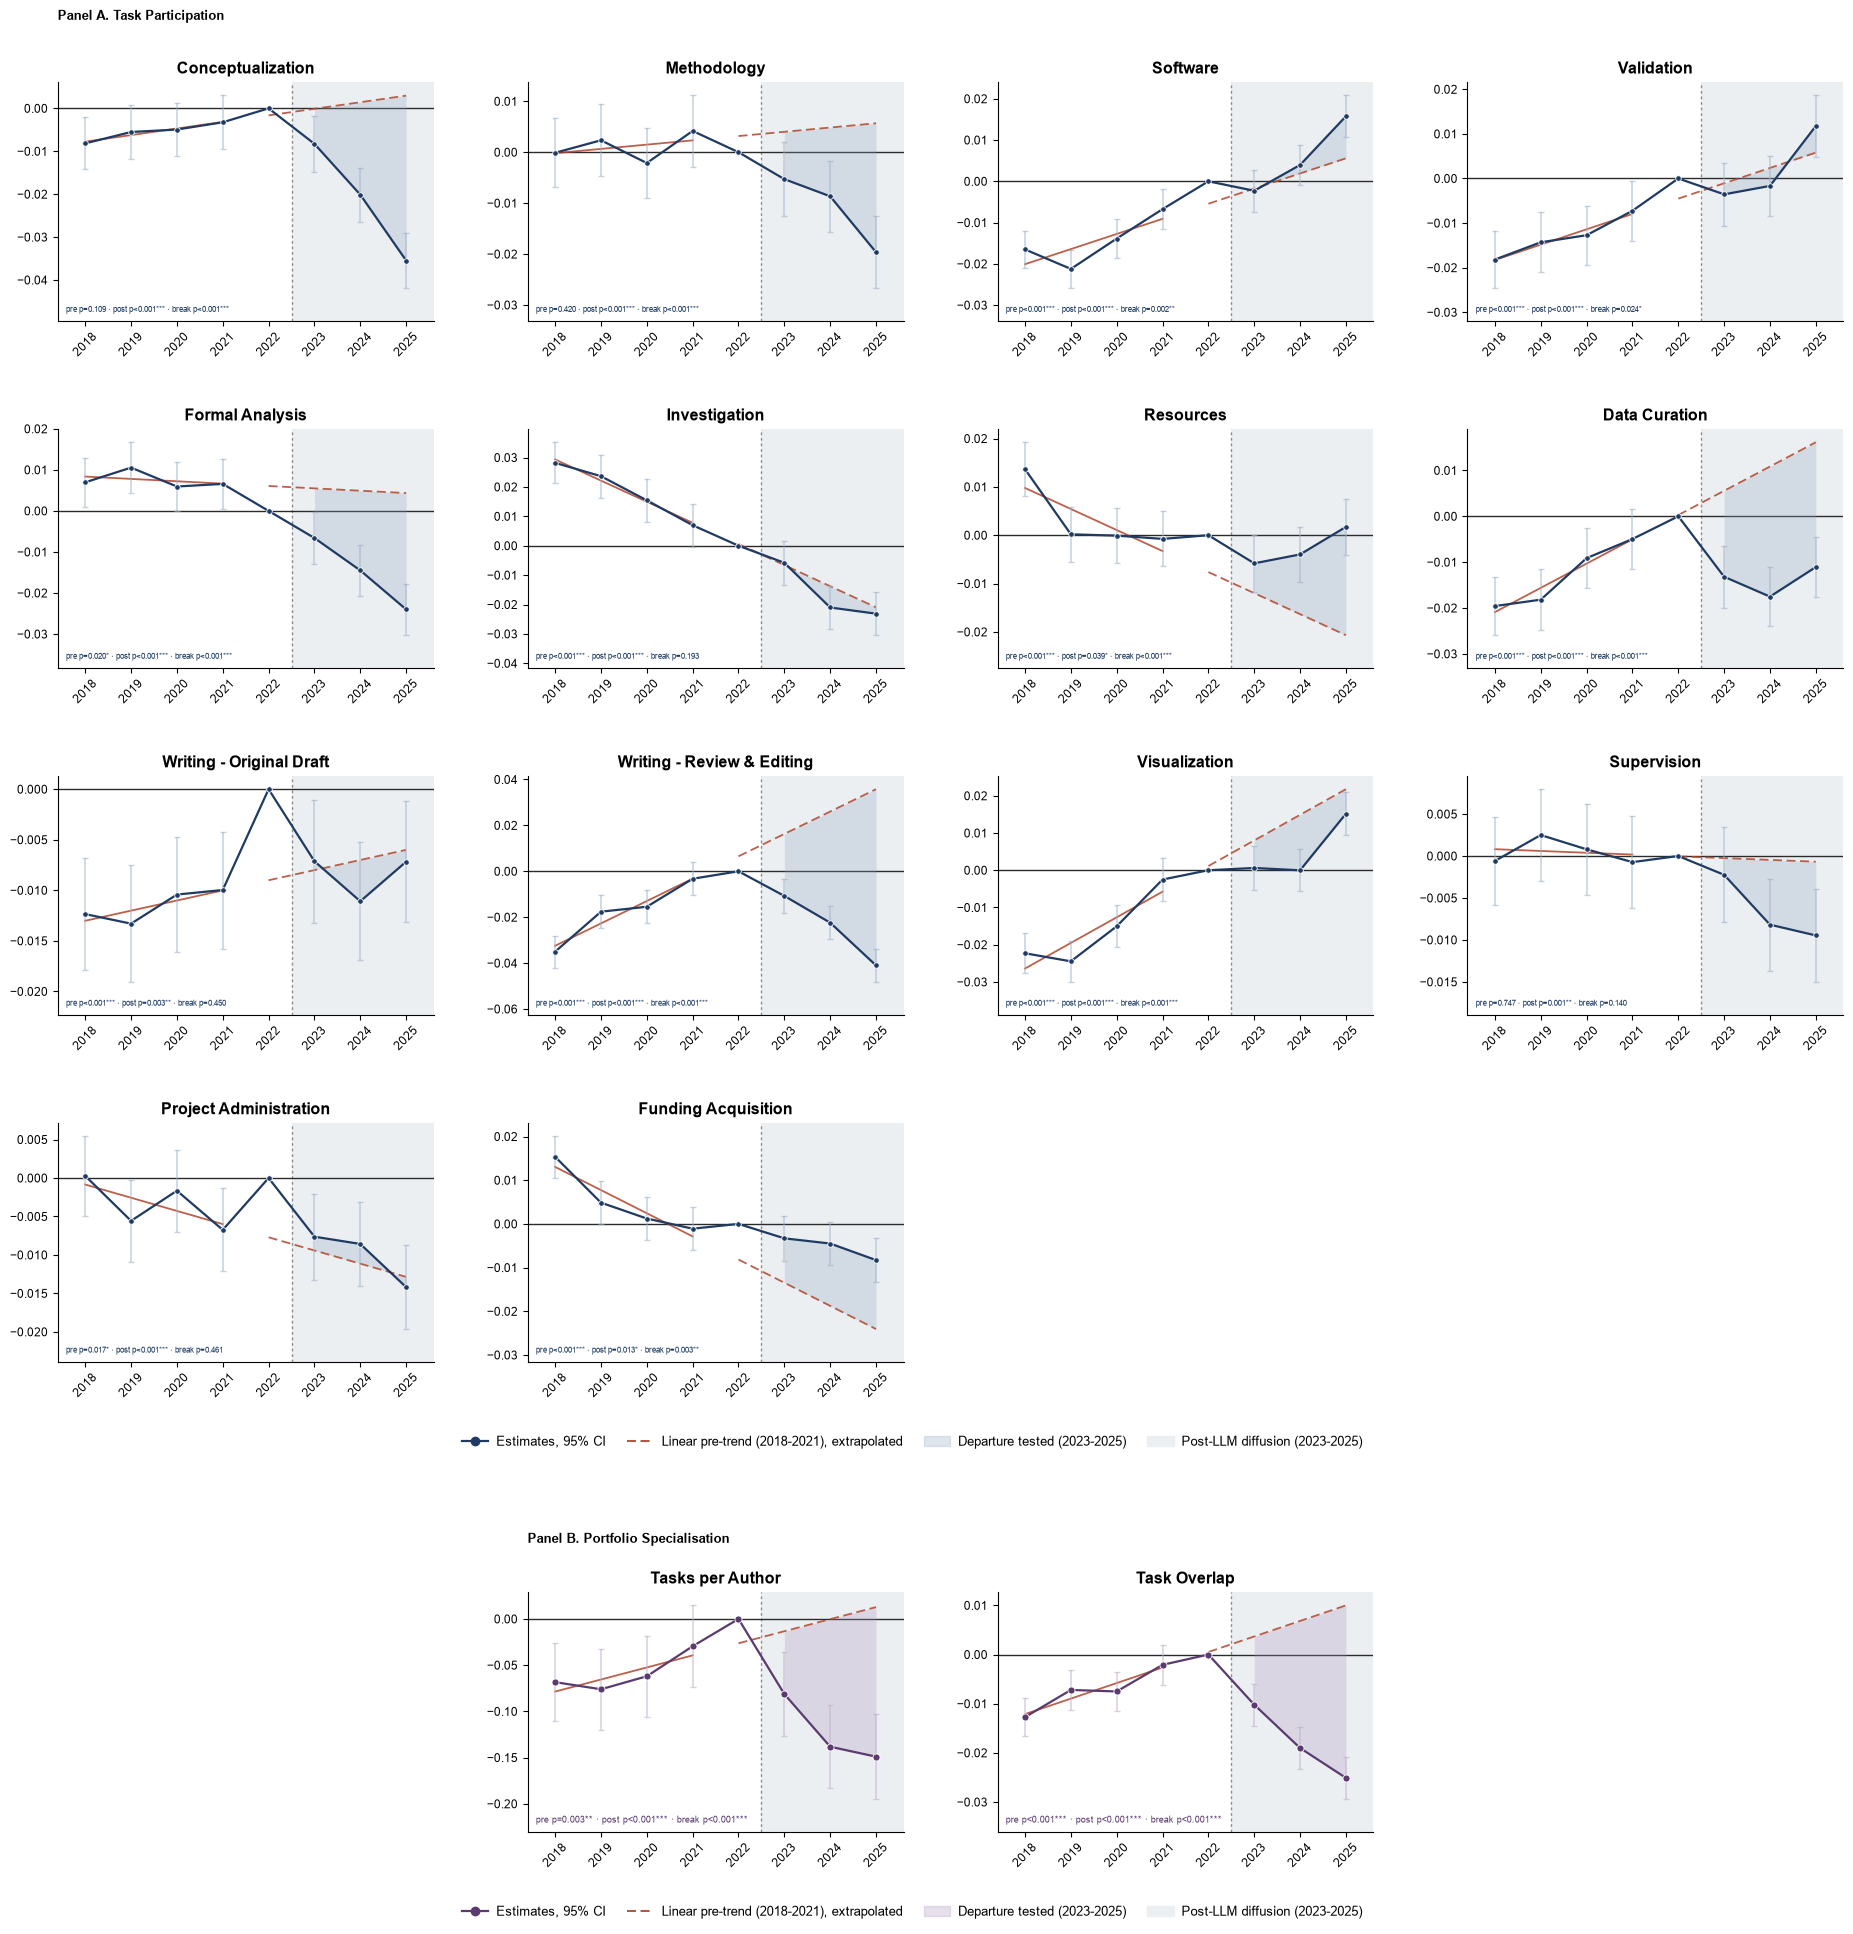

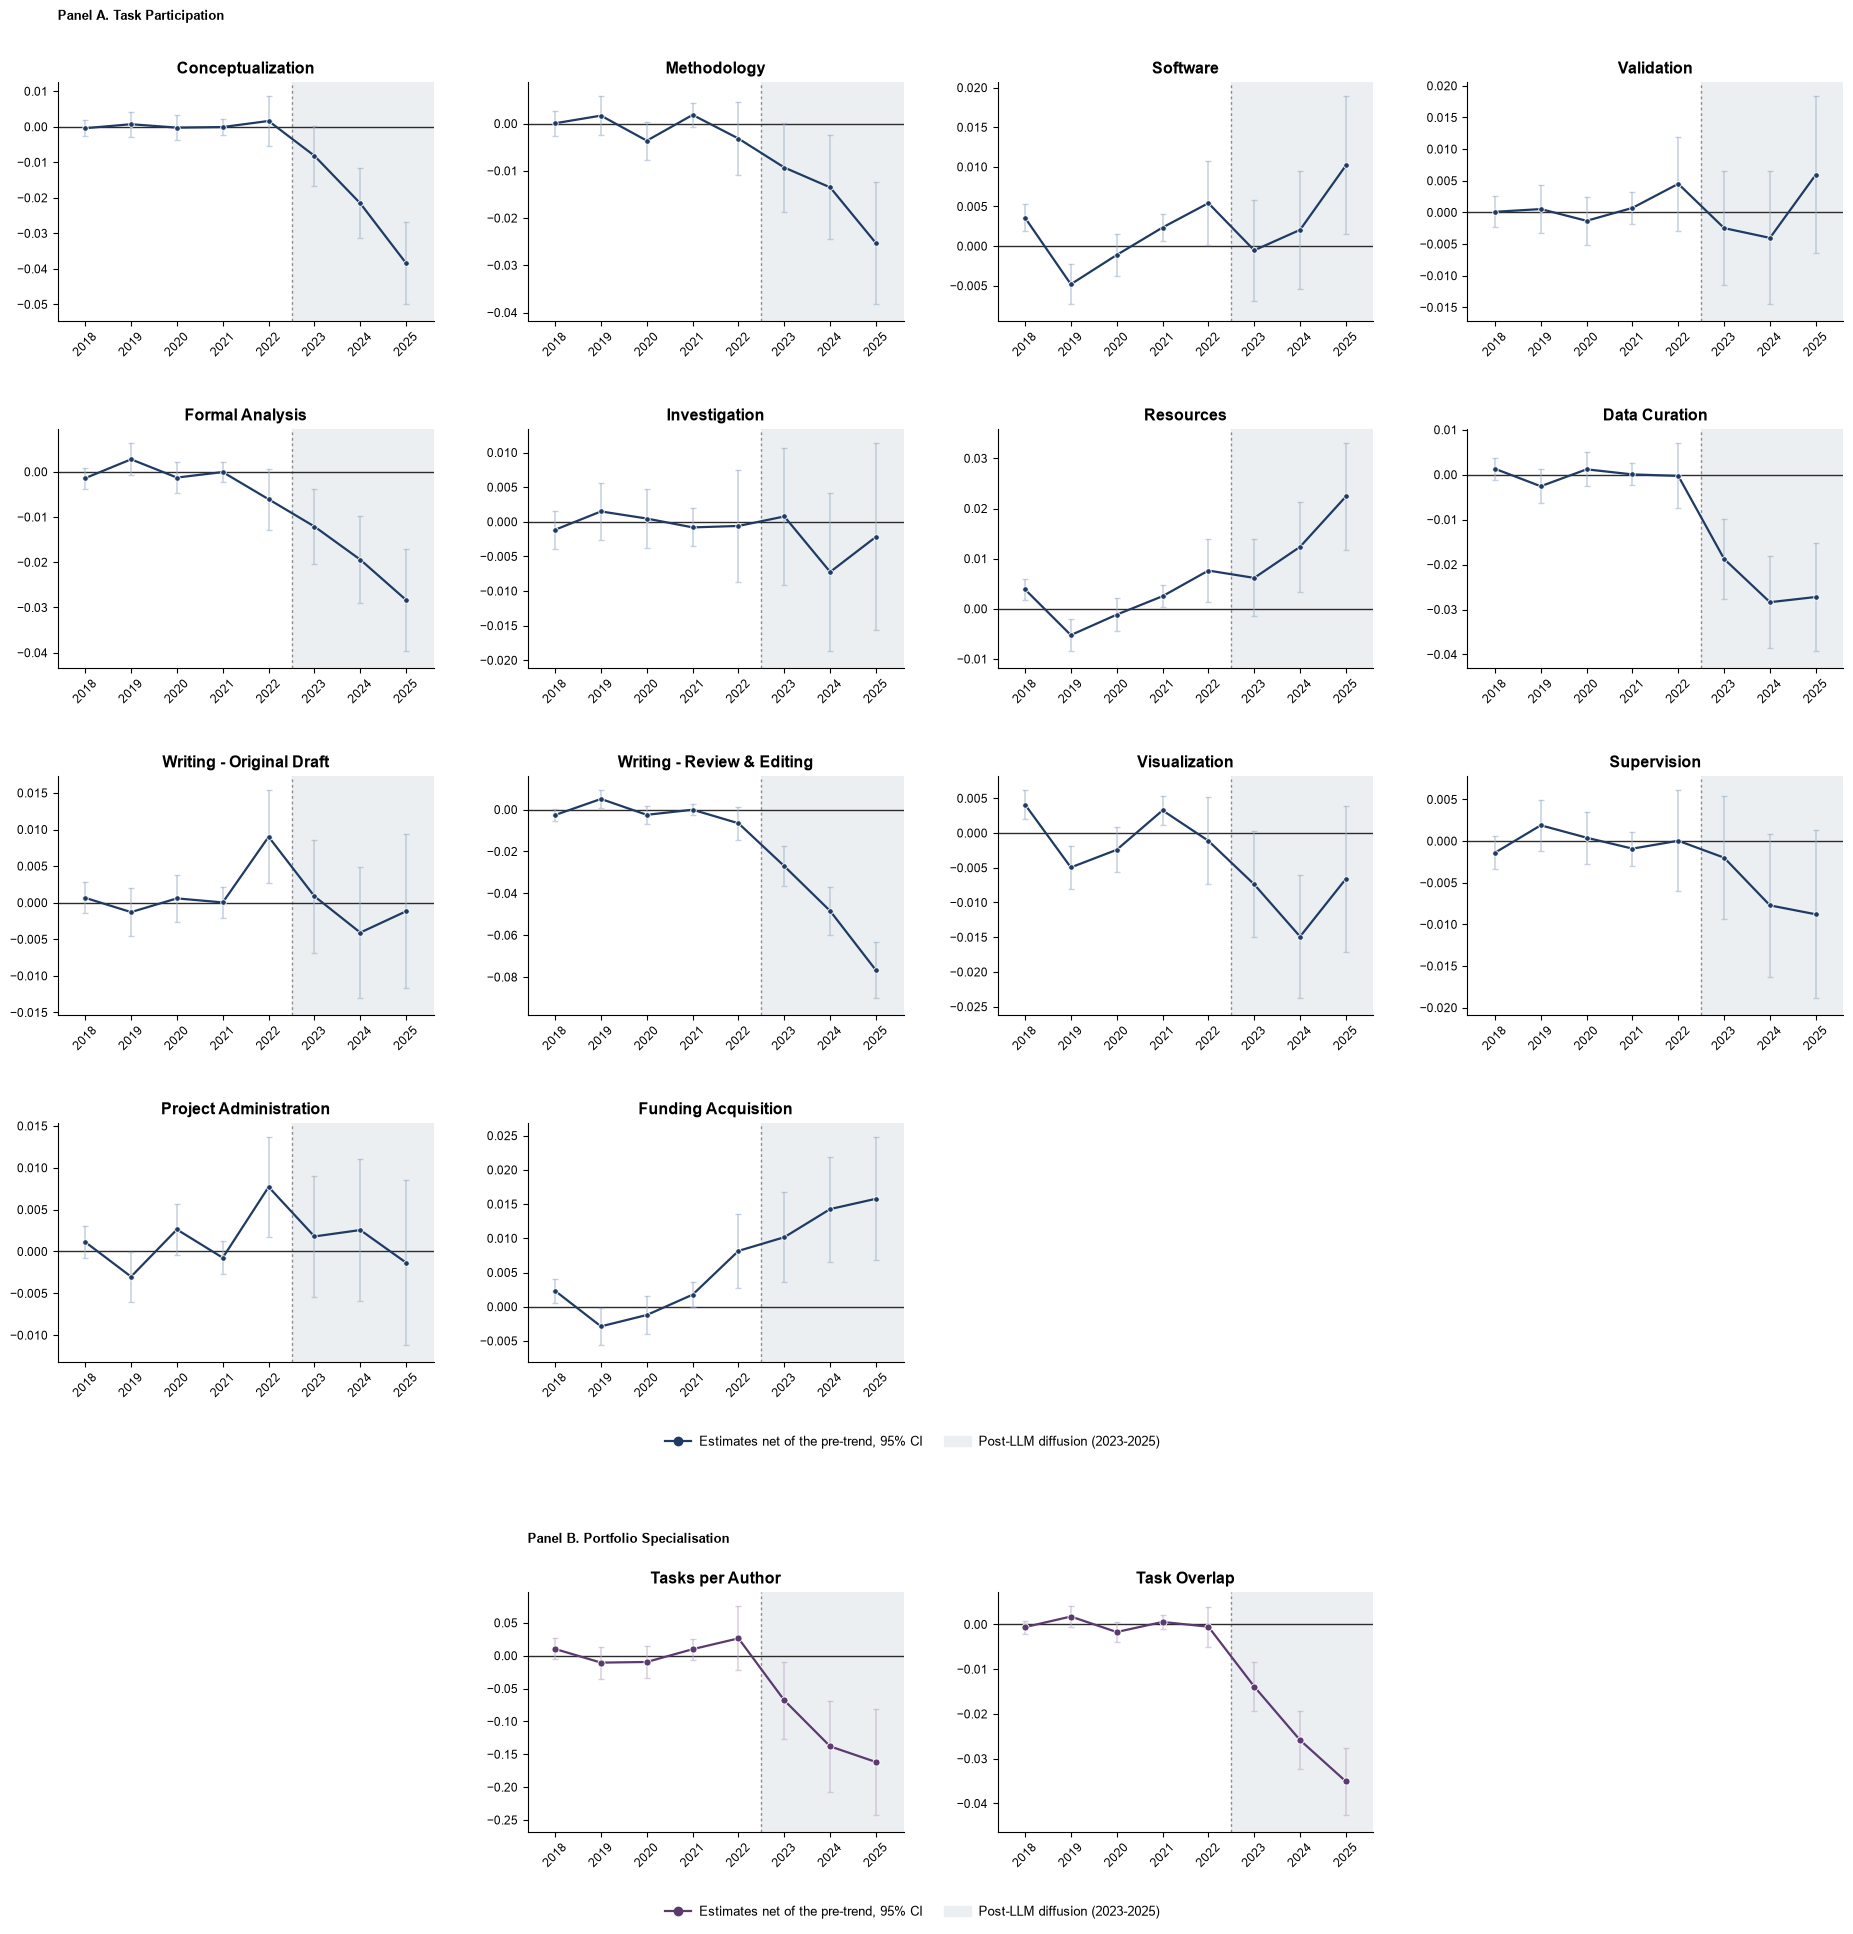


########## Established Teams  (n=14,983) ##########

-- Panel A: the 14 roles, contributor share
     Conceptualization          pre p=0.015*  post p=0.126  break p=0.148  N 14,983
     Methodology                pre p=0.709  post p=0.567  break p=0.514  N 14,983
     Software                   pre p=0.047*  post p=0.200  break p=0.582  N 14,983
     Validation                 pre p=0.618  post p=0.005**  break p=0.267  N 14,983
     Formal Analysis            pre p=0.423  post p=0.234  break p=0.103  N 14,983
     Investigation              pre p=0.647  post p=0.856  break p=0.738  N 14,983
     Resources                  pre p=0.006**  post p=0.100†  break p=0.297  N 14,983
     Data Curation              pre p<0.001***  post p=0.114  break p=0.054†  N 14,983
     Writing - Original Draft   pre p=0.321  post p=0.146  break p=0.794  N 14,983
     Writing - Review & Editing pre p=0.062†  post p=0.980  break p=0.849  N 14,983
     Visualization              pre p<0.001***  post p=0.062

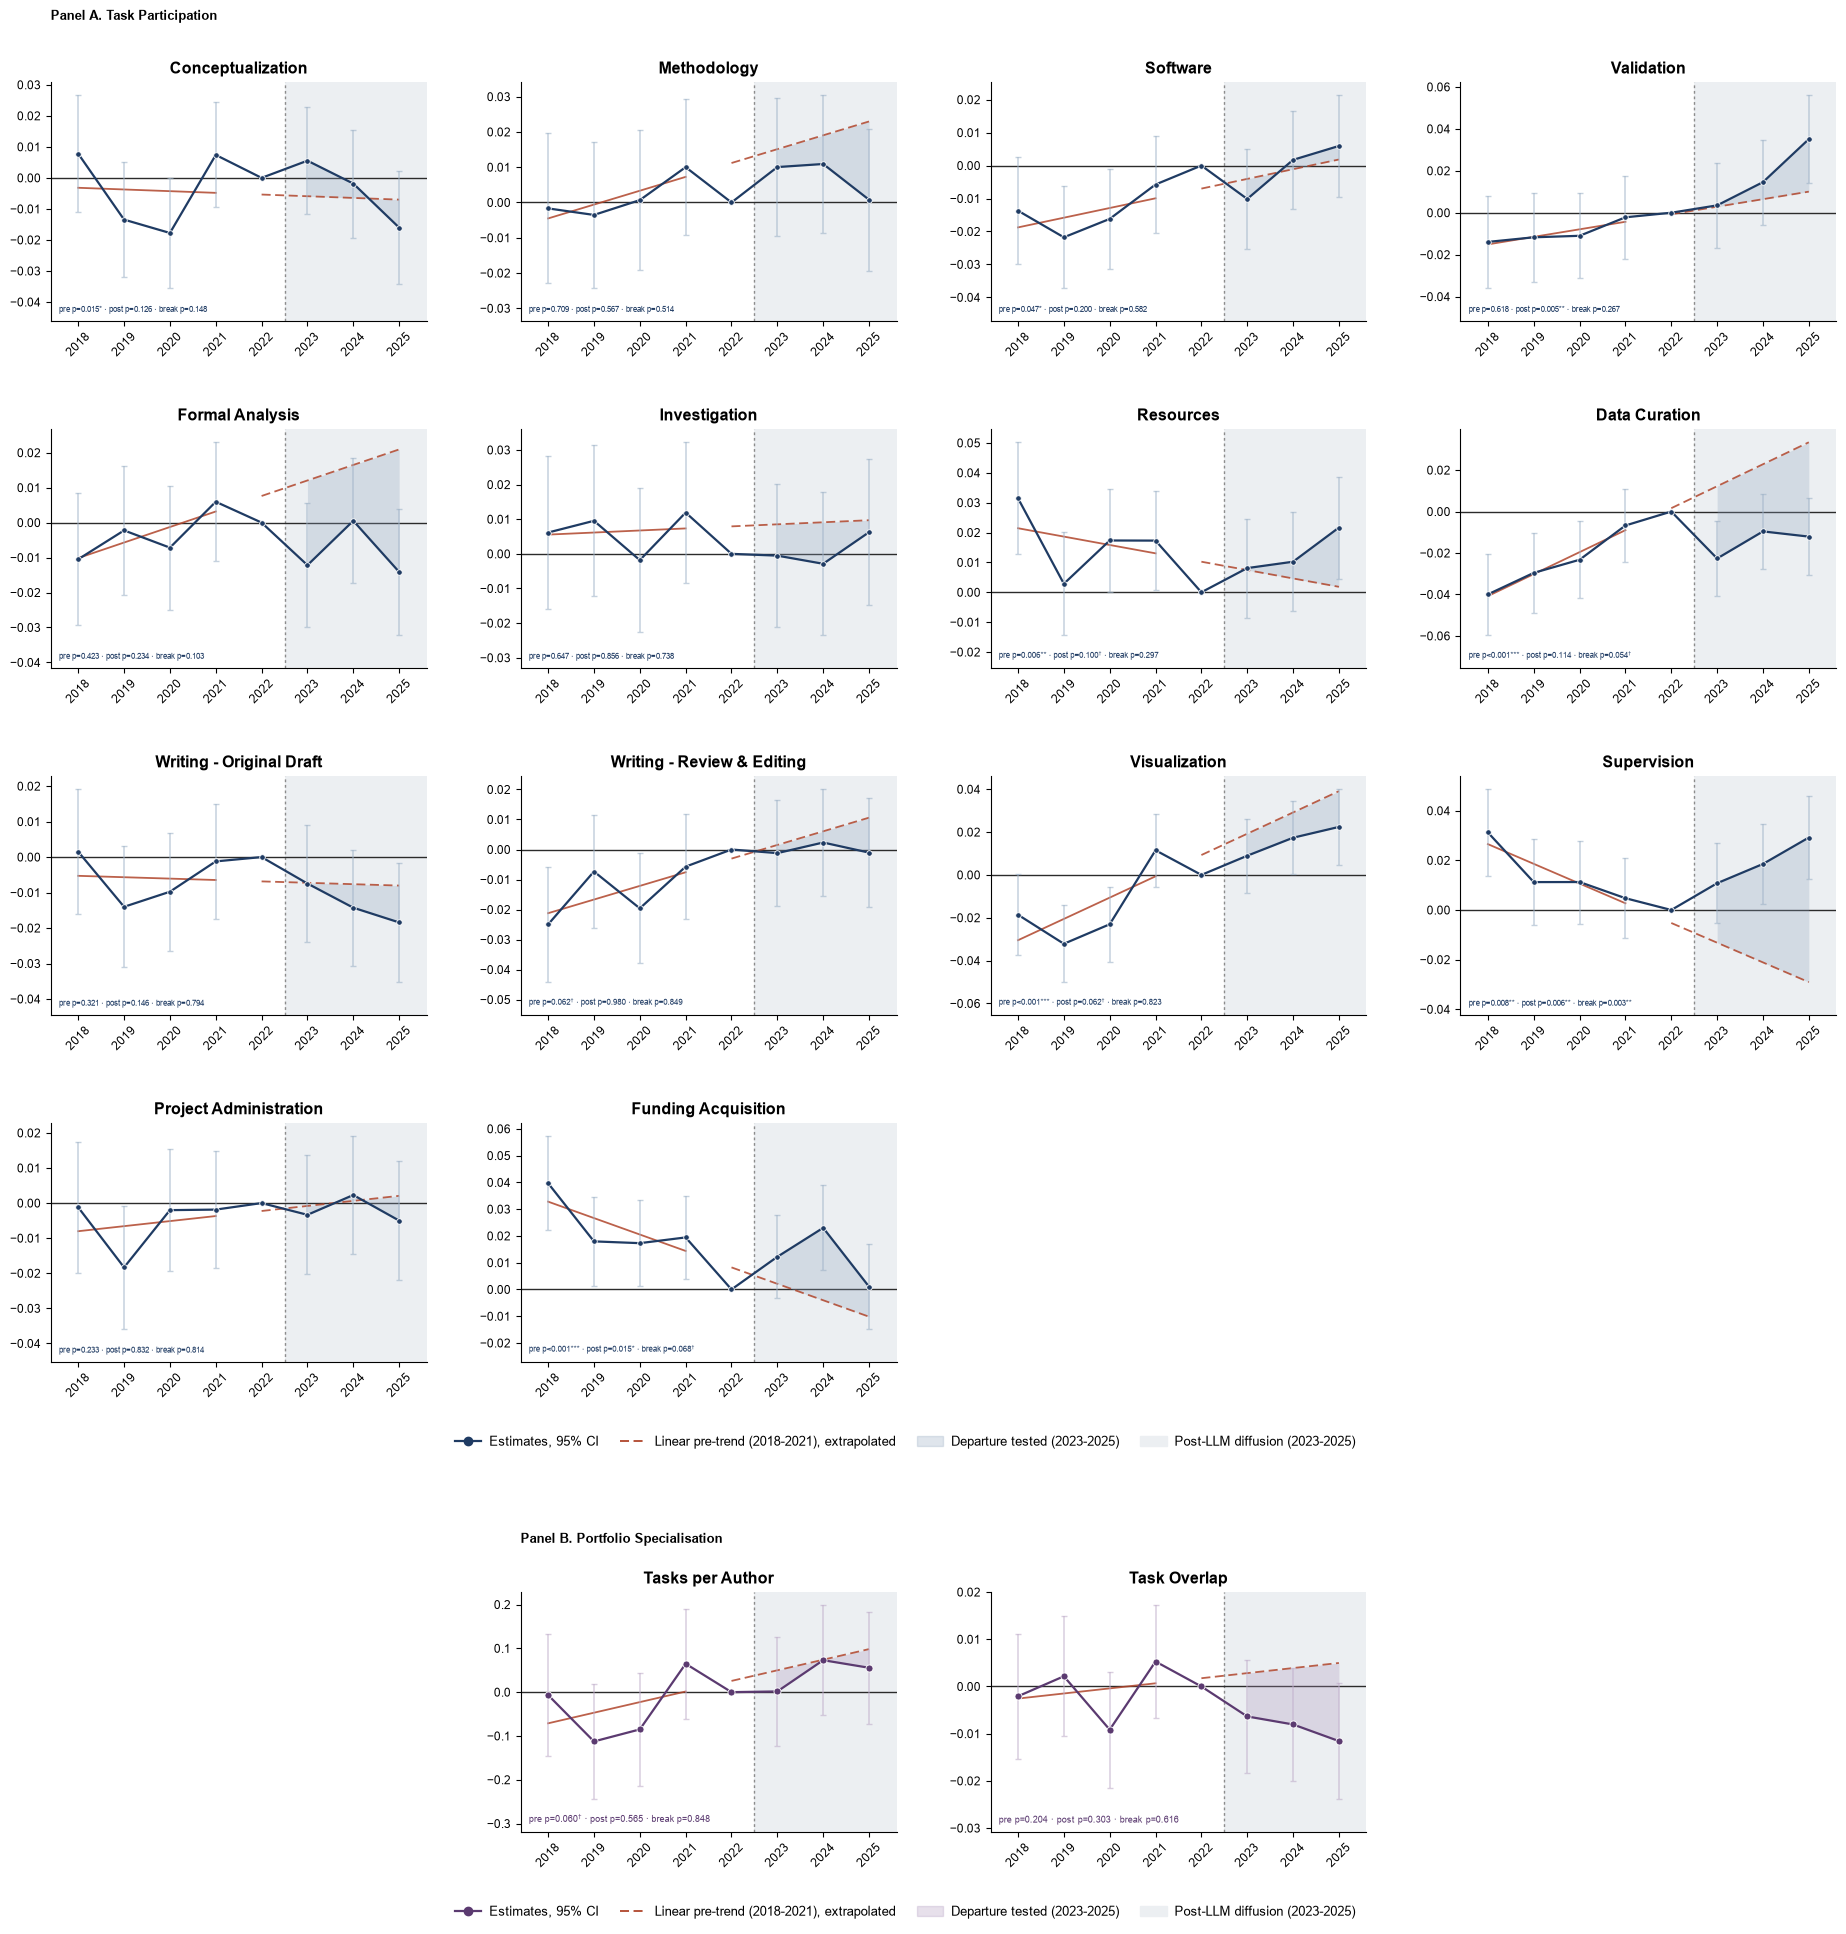

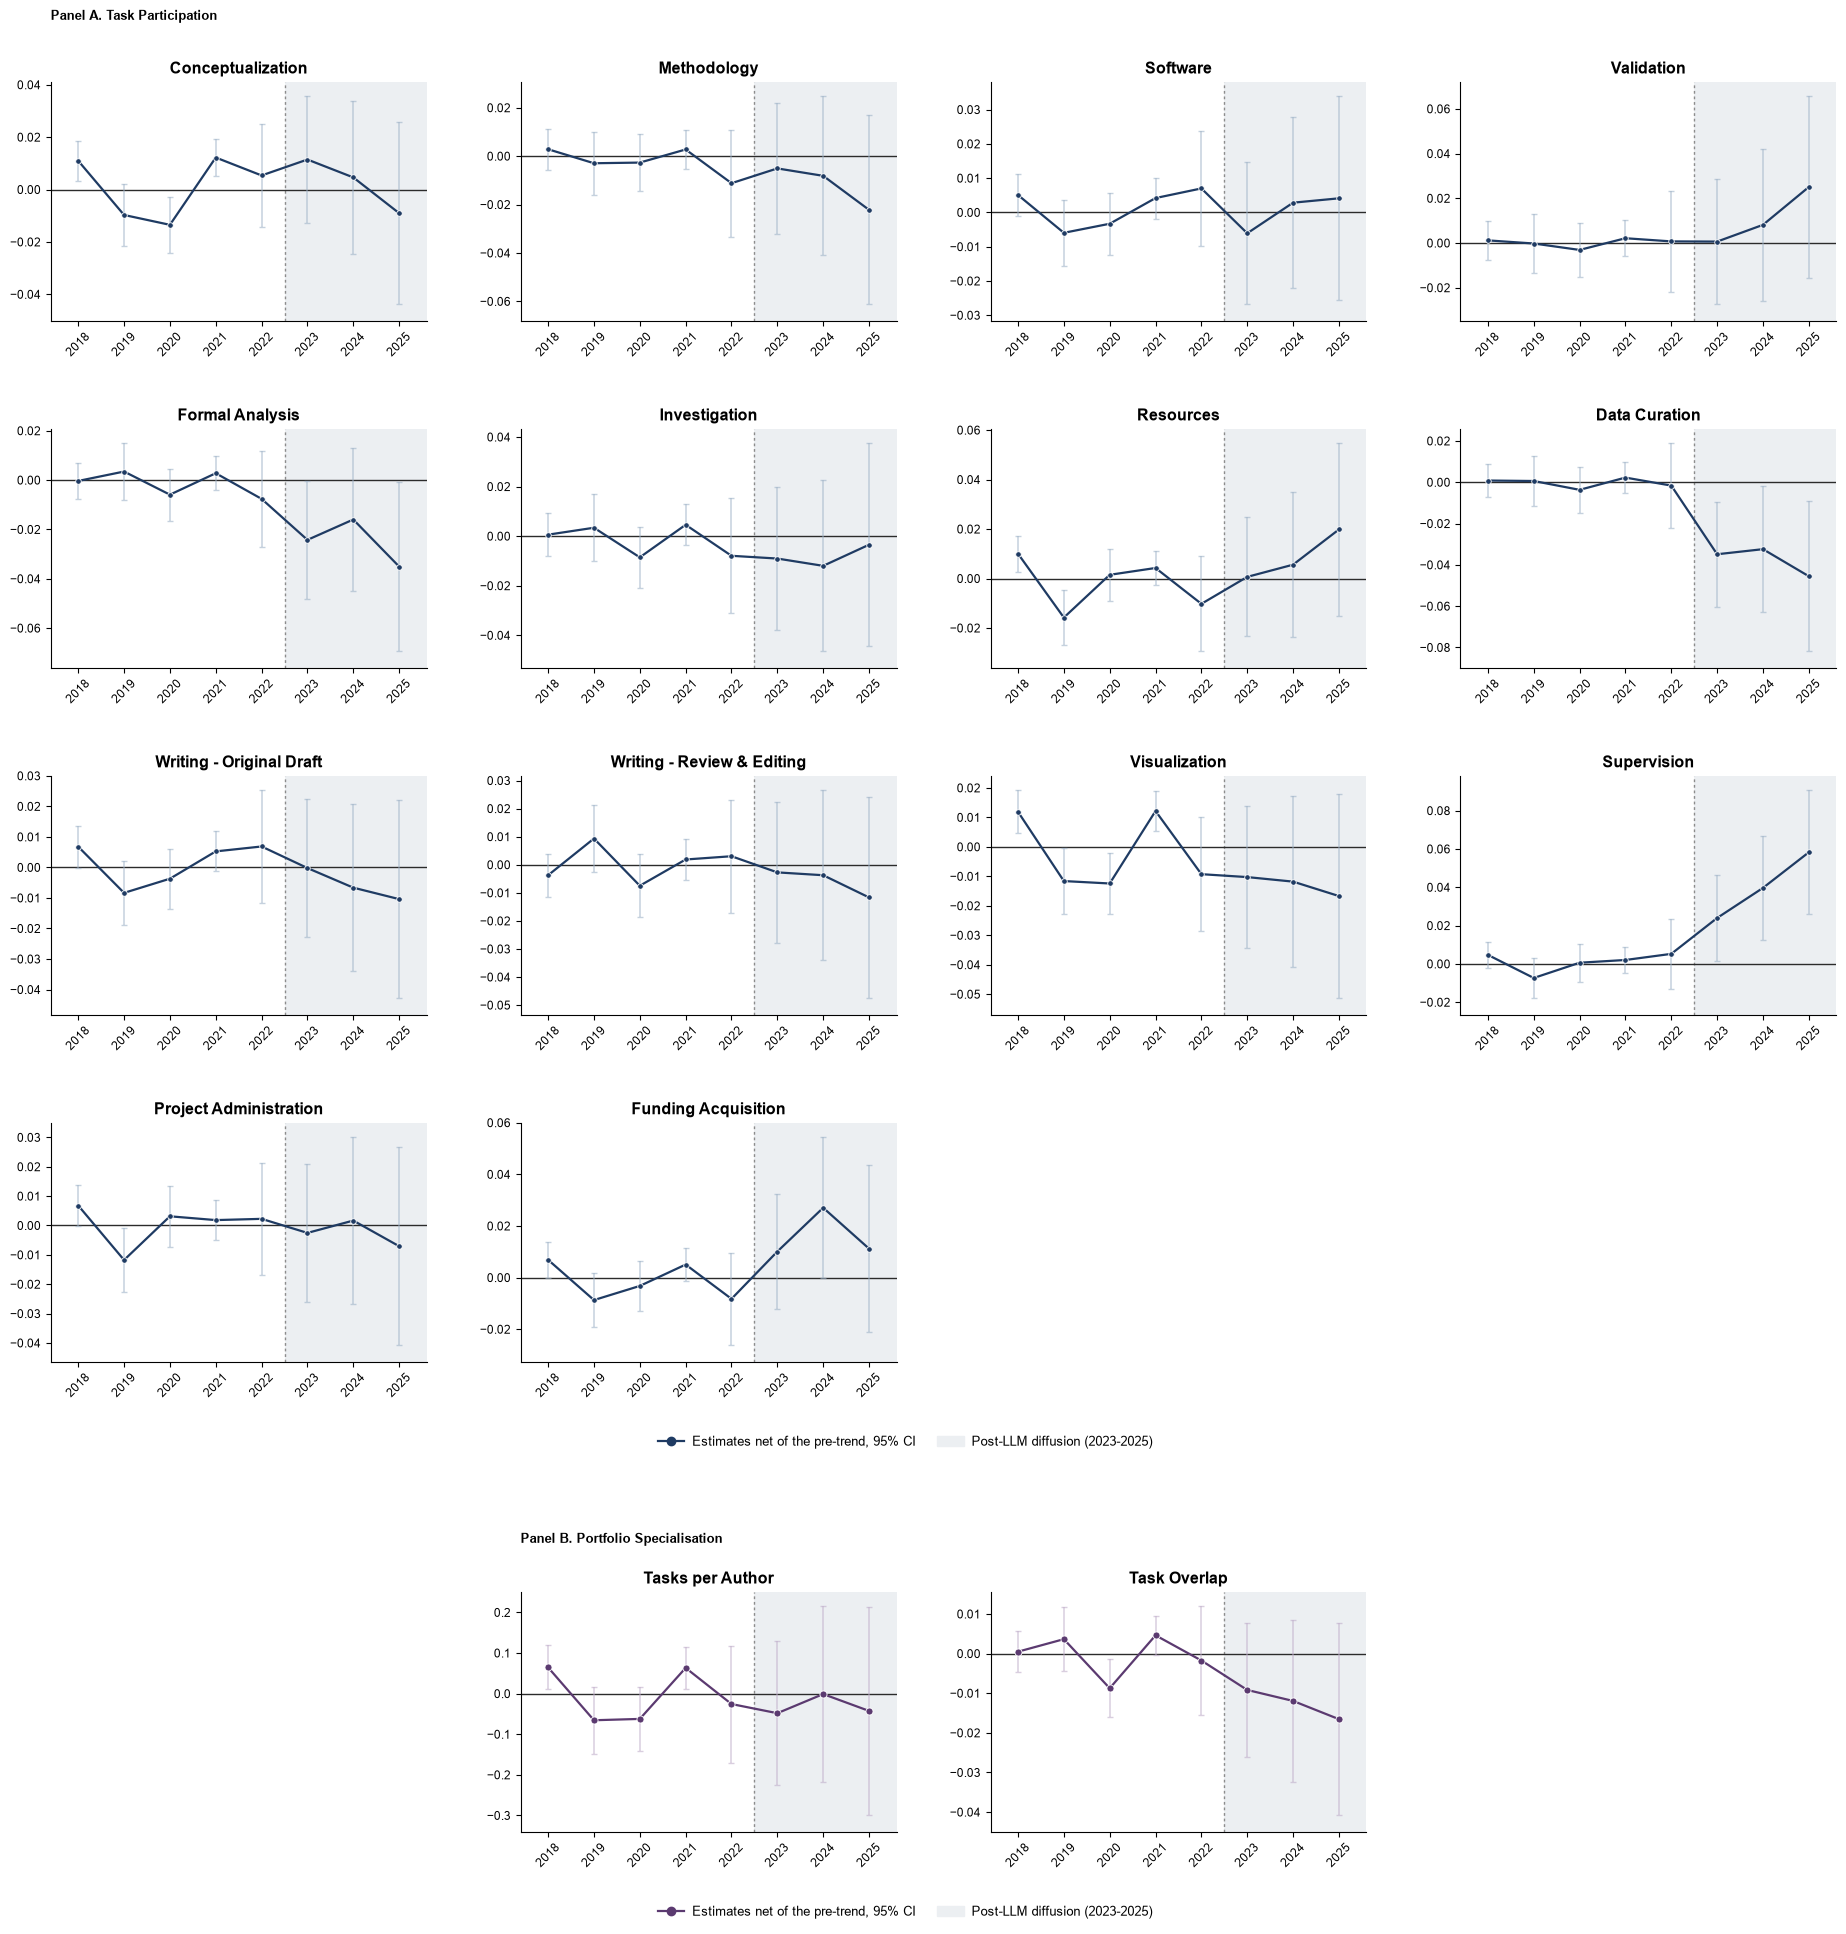


########## Newly Formed Teams  (n=102,228) ##########

-- Panel A: the 14 roles, contributor share
     Conceptualization          pre p=0.235  post p<0.001***  break p<0.001***  N 102,228
     Methodology                pre p=0.494  post p<0.001***  break p=0.011*  N 102,228
     Software                   pre p<0.001***  post p<0.001***  break p<0.001***  N 102,228
     Validation                 pre p<0.001***  post p<0.001***  break p=0.059†  N 102,228
     Formal Analysis            pre p=0.003**  post p<0.001***  break p<0.001***  N 102,228
     Investigation              pre p<0.001***  post p<0.001***  break p=0.327  N 102,228
     Resources                  pre p<0.001***  post p=0.026*  break p<0.001***  N 102,228
     Data Curation              pre p<0.001***  post p<0.001***  break p<0.001***  N 102,228
     Writing - Original Draft   pre p<0.001***  post p=0.026*  break p=0.529  N 102,228
     Writing - Review & Editing pre p<0.001***  post p<0.001***  break p<0.001***  N

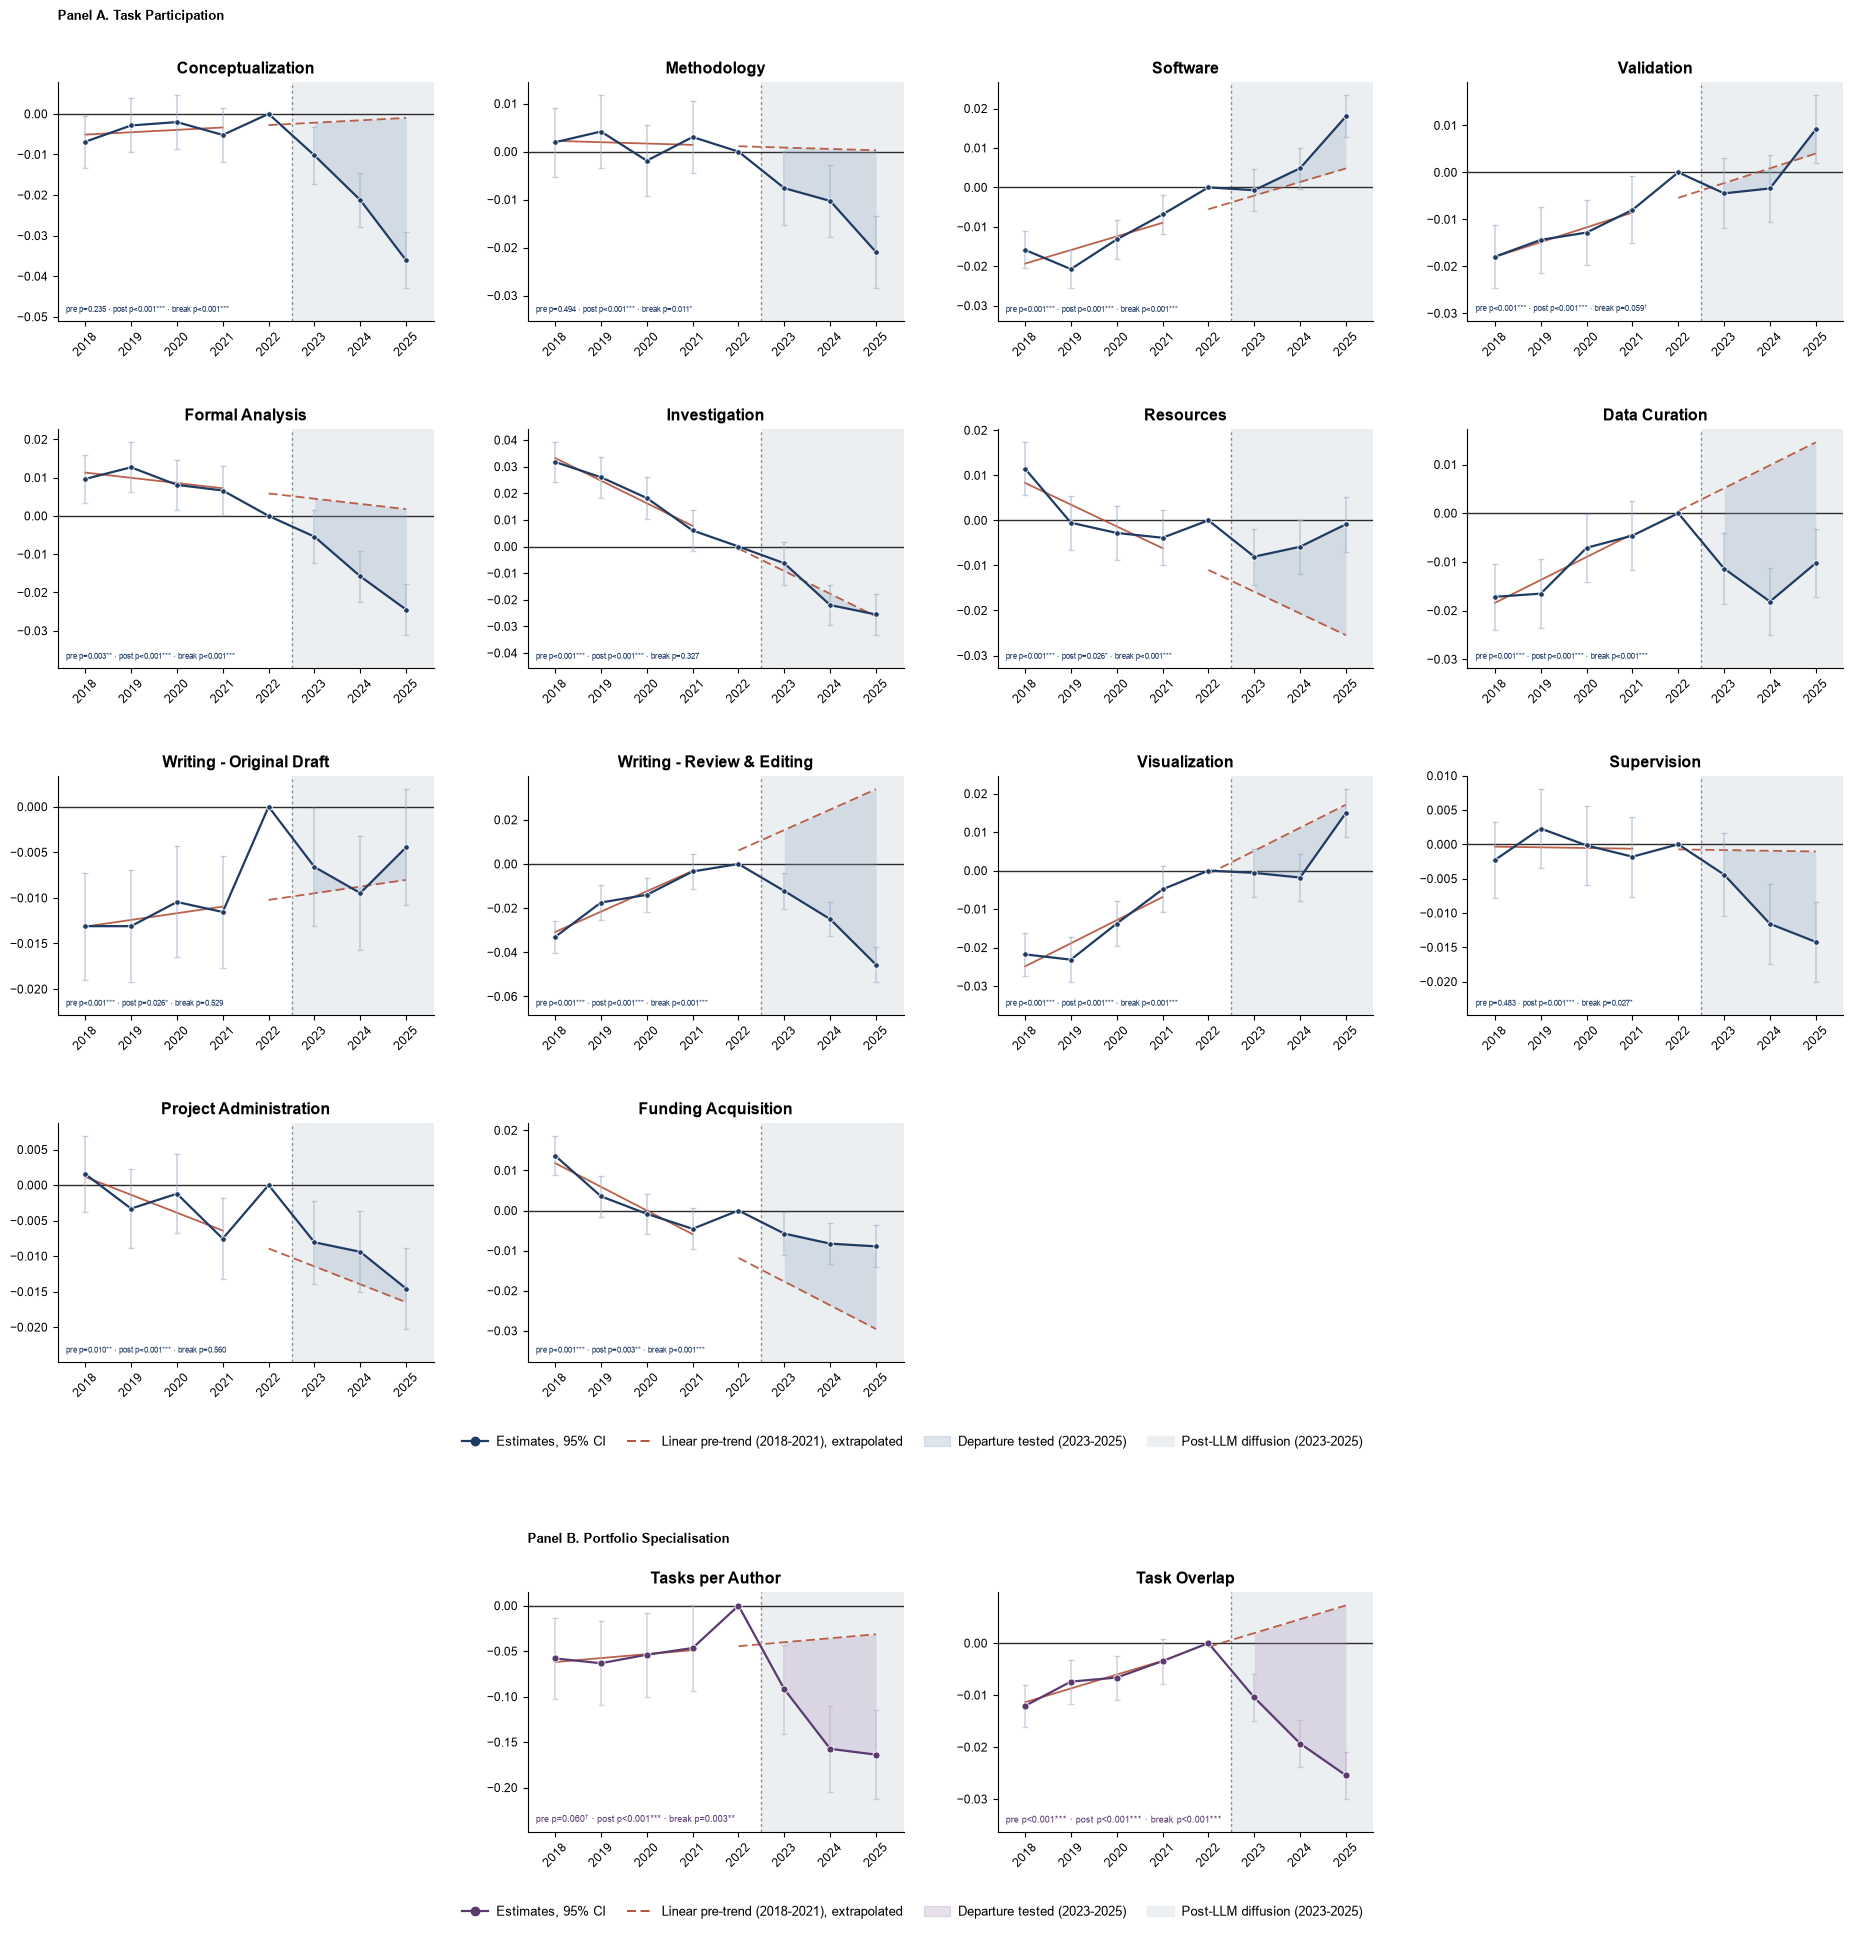

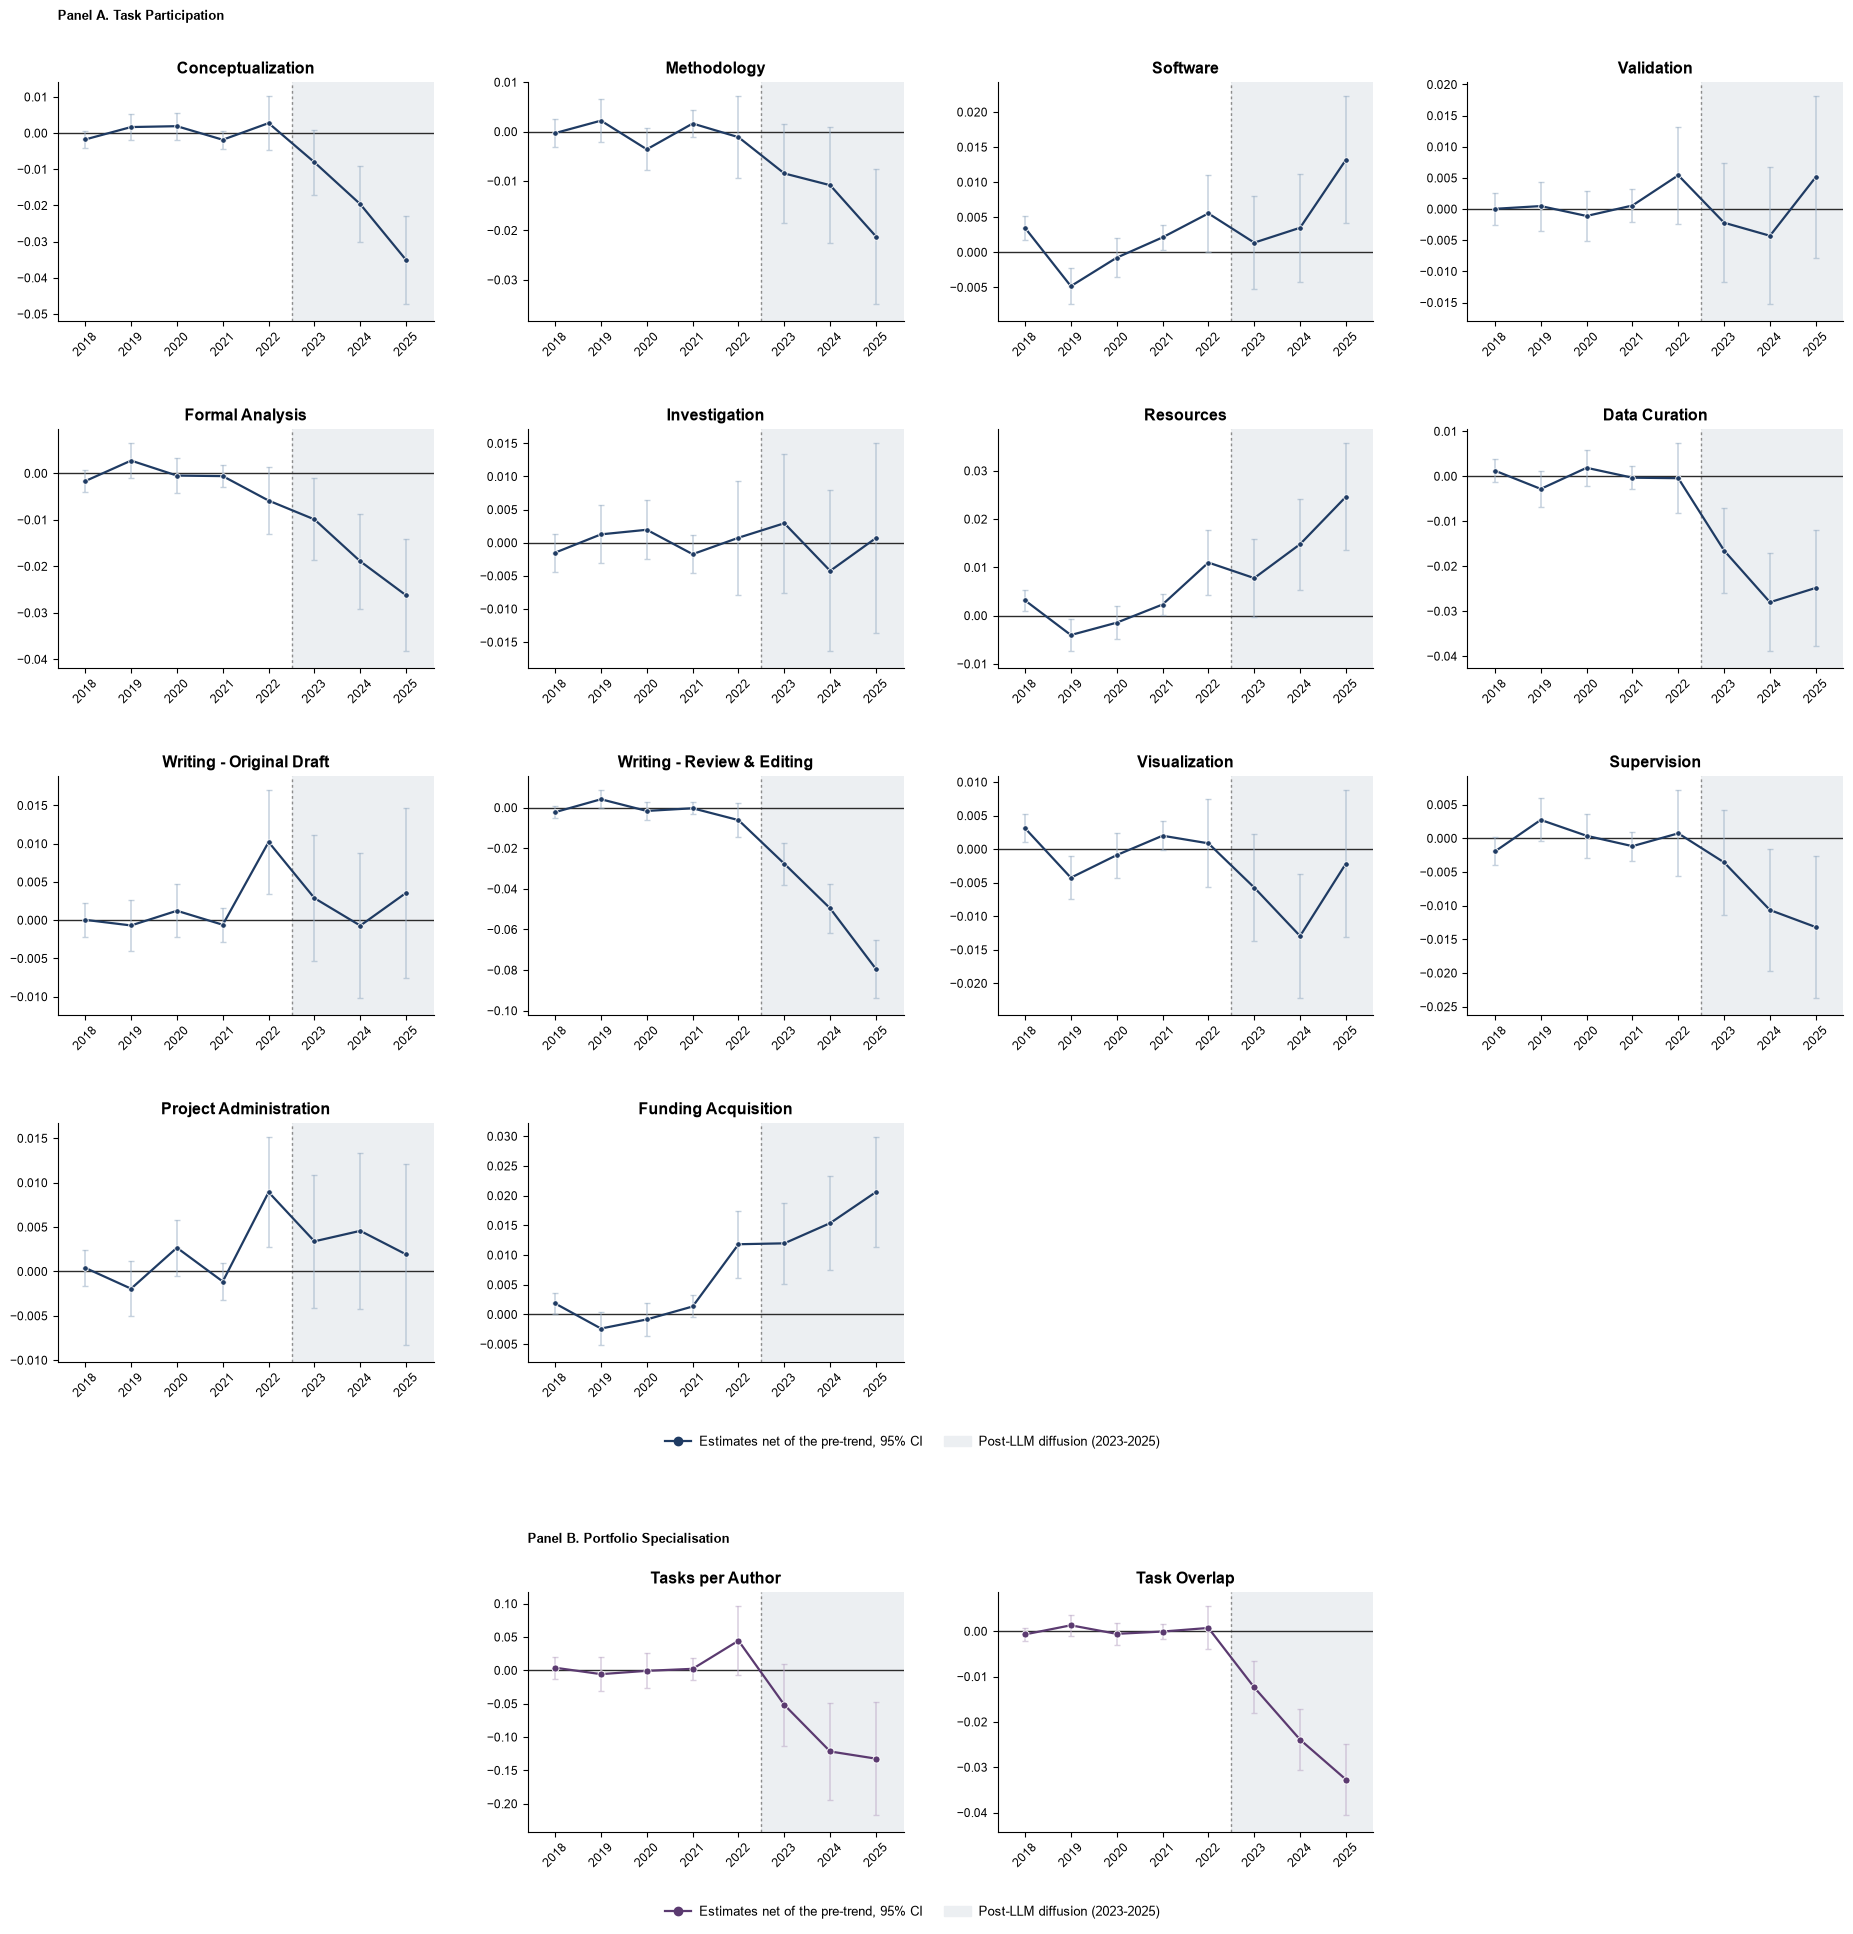

In [12]:
out4 = R.block4(d, controls)

## Block 5 — departures from pre-LLM trends across fields

Table 2. A mark means the 2023–2025 deviation from the field's own linear
pre-trend is jointly significant.

In [13]:
tab5 = R.block5(d, controls)
cols = ["field", "N"] + [f"{s}_mark" for s in C.STAGE_KEYS] \
                      + [f"{c}_mark" for c, _ in C.METRICS]
tab5[cols]


BLOCK 5  departures from pre-LLM trends across fields
    fields kept: 21 (>= 500 papers, >= 10/year)
      Medicine                                   n= 43,792  [++++++]
      Biochemistry, Genetics and Molecular Biolo n= 12,954  [      ]
      Environmental Science                      n=  7,775  [  .+  ]
      Agricultural and Biological Sciences       n=  7,707  [    . ]
      Psychology                                 n=  6,384  [   +  ]
      Social Sciences                            n=  6,172  [ ++. +]
      Engineering                                n=  4,743  [  .   ]
      Neuroscience                               n=  4,453  [    + ]
      Health Professions                         n=  3,994  [      ]
      Computer Science                           n=  3,398  [+   + ]
      Immunology and Microbiology                n=  2,920  [     +]
      Economics, Econometrics and Finance        n=  2,471  [+ +++ ]
      Business, Management and Accounting        n=  1,505  [      ]


,field,N,ideation_mark,data_and_coding_mark,execution_mark,communication_mark,coordination_mark,funding_resources_mark,avg_tasks_per_author_mark,avg_jaccard_mark
0,Medicine,43792,**,***,**,***,*,***,***,***
1,"Biochemistry, Genetics and Molecular Biology",12954,,,,,,,,†
2,Environmental Science,7775,,,†,*,,,†,*
3,Agricultural and Biological Sciences,7707,,,,,†,,,
4,Psychology,6384,,,,*,,,,*
5,Social Sciences,6172,,**,**,†,,*,**,
6,Engineering,4743,,,†,,,,,
7,Neuroscience,4453,,,,,*,,,
8,Health Professions,3994,,,,,,,,
9,Computer Science,3398,*,,,,*,,,


## Block 6 — decomposing new teams


BLOCK 6  newly formed teams by prior-collaboration band
hybrid teams 88,831 | purely new 13,397 (first)
  0%–25%     n = 15,464
  25%–50%    n = 21,357
  50%–75%    n = 38,988
  excluded: 26,419 hybrids at 75% or more, 0 without a ratio

########## 0%–25%  (n=15,464) ##########

-- task participation
     Ideation                   pre p=0.100  post p<0.001***  break p=0.056†  N 15,464
     Data and Coding            pre p=0.005**  post p=0.116  break p=0.059†  N 15,464
     Execution                  pre p=0.076†  post p<0.001***  break p=0.036*  N 15,464
     Writing                    pre p=0.830  post p<0.001***  break p=0.024*  N 15,464
     Coordination               pre p=0.750  post p<0.001***  break p=0.090†  N 15,464
     Funding and Resources      pre p=0.011*  post p=0.061†  break p=0.048*  N 15,464

-- portfolio specialisation
     Tasks per Author           pre p=0.269  post p<0.001***  break p=0.066†  N 15,464
     Task Overlap               pre p=0.330  post p<0.001***

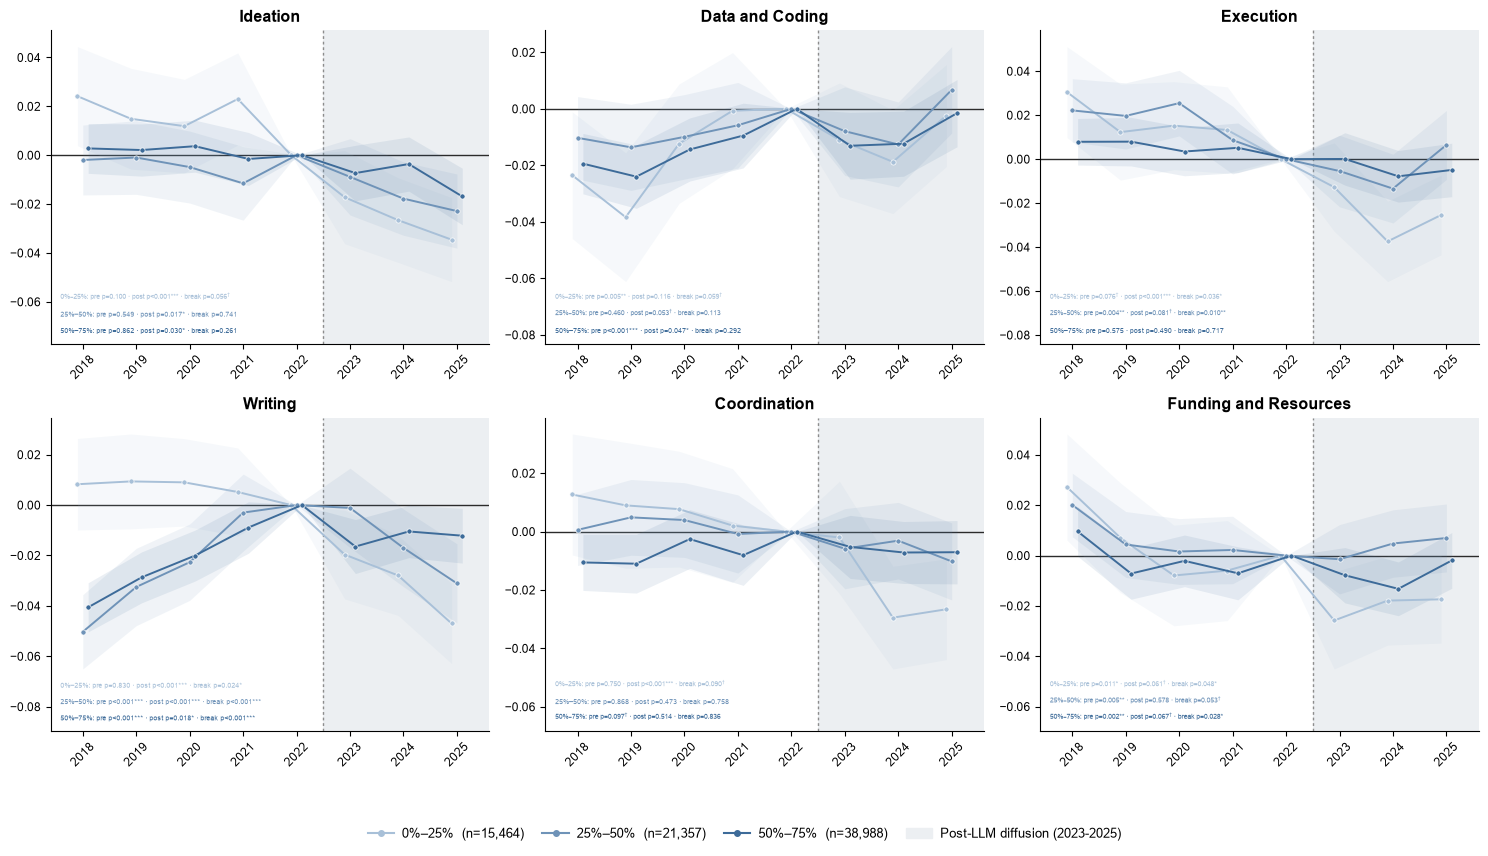

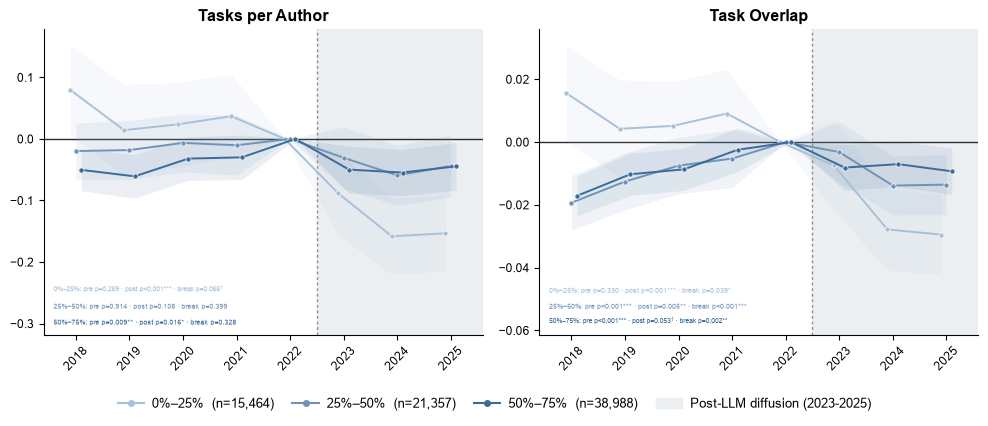

In [14]:
out6 = R.block6(d, controls)

## The log

One row per outcome. `b_{year}` is the event-study coefficient against
2022 — the magnitude quoted in Section 4 — with `se_{year}` beside it.
`dev_{year}` is that same coefficient net of the extrapolated pre-trend,
which is what the trend-break test aggregates and what the detrended
figures plot; the two differ by the trend and should not be confused.


In [15]:
log  = R.save_results()
T.headline_table(log, block="H1", kind="share")      # participation, all teams


saved C:\Users\iogec\Downloads\llms_scientific_work\llms_scientific_work\outputs\event_studies.csv  (114 event studies)


,label,group,N,pp_vs_2022,pp_vs_trend,pre_p,post_p,break_p,p_dev_2025
0,Ideation,all,117211,-2.6,-2.1,0.7381,0.0000,0.0002,0.0003
1,Data and Coding,all,117211,-0.0,-1.2,0.0000,0.0000,0.0006,0.0621
2,Execution,all,117211,-0.9,-1.1,0.0194,0.0001,0.0021,0.0869
3,Writing,all,117211,-2.7,-5.3,0.0000,0.0000,0.0000,0.0000
4,Coordination,all,117211,-1.4,-1.2,0.5136,0.0001,0.0440,0.0355
5,Funding and Resources,all,117211,-0.3,2.4,0.0000,0.3072,0.0007,0.0001


In [16]:
T.headline_table(log, block="H2")                    # specialisation, all teams


,label,group,N,b_2025,dev_2025,pre_p,post_p,break_p,p_dev_2025
0,Tasks per Author,all,117211,-0.080,-0.085,0.0043,0.0,0.0001,0.0
1,Task Overlap,all,117211,-0.018,-0.030,0.0000,0.0,0.0000,0.0


In [17]:
T.headline_table(log, block="H3", kind="share")      # participation by team type


,label,group,N,pp_vs_2022,pp_vs_trend,pre_p,post_p,break_p,p_dev_2025
0,Ideation,existing,14983,-1.2,0.5,0.0994,0.2311,0.1608,0.7604
1,Data and Coding,existing,14983,-1.3,-2.4,0.0007,0.0445,0.3466,0.1979
2,Execution,existing,14983,0.5,-0.6,0.8688,0.3617,0.4092,0.7284
3,Writing,existing,14983,-0.3,0.8,0.2755,0.5070,0.1433,0.5377
4,Coordination,existing,14983,1.0,4.6,0.2017,0.5941,0.0719,0.0127
5,Funding and Resources,existing,14983,2.2,1.8,0.0003,0.0422,0.8033,0.3385
6,Ideation,new,102228,-2.7,-1.9,0.2707,0.0000,0.0054,0.0025
7,Data and Coding,new,102228,0.2,-0.9,0.0000,0.0001,0.0011,0.1659
8,Execution,new,102228,-1.0,-1.0,0.0040,0.0000,0.0009,0.1143
9,Writing,new,102228,-3.0,-5.6,0.0000,0.0000,0.0000,0.0000


In [18]:
T.headline_table(log, block="H3", kind="metric")     # specialisation by team type


,label,group,N,b_2025,dev_2025,pre_p,post_p,break_p,p_dev_2025
0,Tasks per Author,existing,14983,0.009,0.047,0.1742,0.6659,0.5291,0.4140
1,Task Overlap,existing,14983,0.000,-0.003,0.4690,0.8975,0.9073,0.7765
2,Tasks per Author,new,102228,-0.087,-0.082,0.0562,0.0000,0.0003,0.0001
3,Task Overlap,new,102228,-0.019,-0.029,0.0000,0.0000,0.0000,0.0000
